# Think on the Graph: diagnose a student's explanation of a Java program
#
This notebook runs the repository's own code (`src/`) on `data/raw/chapter1_kg_new.json`. Nothing is copied or rewritten.
#
**Each time you run cell 5 it reads** the Java program, the question and the student's answer, and shows every
step: the subgraph Stage 1 takes from the code, the clauses and start concepts, each depth of the walk (pruning,
labels, clause coverage) and the final diagnosis (held misconceptions, the labels folded as shadows of them, root cause, level per concept, overall level).
#
Run cells 1 to 3 once per session (they load the code and the knowledge graph and define the pipeline), then
use cells 4 and 5 as often as you like. Stage 2 is exactly the repository's `python src/traverse.py`: Claude through the Claude CLI (`claude -p --model claude-opus-5-5`, the CLI's own login on this computer, no API key), used only to prune and label edges; every other step
is a graph lookup or a rule. Replies are cached, so the same input twice costs nothing.

In [1]:
# 1. Load the repository's code and the knowledge graph
import sys, os, json, re, importlib, subprocess
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "traverse.py").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import utils, preprocessing, model, prompts, traverse
for m in (utils, preprocessing, model, prompts, traverse):
    importlib.reload(m)
from utils import load_kg, load_config
KG = load_kg()
CFG_ALL = load_config()
print(f"repository: {ROOT}")
print(f"knowledge graph: {len(KG['concepts'])} concepts, {len(KG['edges'])} edges, "
      f"{len(KG['misconceptions_and_errors'])} misconception / error records")

# the Claude CLI: Stage 2 calls `claude -p` exactly as src/traverse.py does, with this computer's login
env = {k: v for k, v in os.environ.items() if k != "CLAUDECODE"}
try:
    r = subprocess.run(["claude", "-p", "Reply with the single word OK."], capture_output=True, text=True, timeout=180, env=env, shell=(os.name == "nt"))
    out = (r.stdout + r.stderr).strip()
    CLAUDE_OK = r.returncode == 0 and "not logged in" not in out.lower() and bool(r.stdout.strip())
except Exception as exc:  # the CLI is missing
    out, CLAUDE_OK = str(exc), False
print("claude -p check:", out[:200])
print("Claude CLI ready: Stage 2 will run" if CLAUDE_OK else "Claude CLI not ready: run `claude` once in a terminal and log in, then run this cell again")


repository: C:\Users\magnu\OneDrive\Desktop\ES_VIterbi_Personalized_Learning
knowledge graph: 173 concepts, 1939 edges, 296 misconception / error records


claude -p check: OK
Claude CLI ready: Stage 2 will run


## 2. Drawing helpers (run once)

In [2]:
# Drawing and log-reading helpers
import math
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import networkx as nx
import pandas as pd
from IPython.display import display, Markdown, HTML

FIG_W, FIG_H = 24, 14          # inches; every walk figure uses this size
LABEL_COLOUR = {"held": "#d62728", "correct": "#2ca02c", "broken": "#d62728", "confirmed": "#2ca02c",
                "shown": "#9467bd", "not applied": "#c7c7c7"}
LEVEL_COLOUR = {"L0": "#f4a3a3", "L1": "#f7c99b", "L2": "#f7e59b", "L3": "#bfe3b4", "L4": "#7fcf8f"}

# ---- reading the traversal log (its line formats are fixed by src/traverse.py)
R_DEPTH = re.compile(r"^--- depth (\d+): current concepts \[(.*)\]")
R_PRUNE = re.compile(r"^  (\S+) \(([^)]+)\): (\d+) candidates -> kept ?(.*)$")
R_LABEL = re.compile(r'^    (\S+) -> (.+?) \(([0-9.]+)\) "(.*)"$')
R_KEPT = re.compile(r"^  kept: (.*)$")
R_COVER = re.compile(r"^  clause coverage: (.*)$")
R_BRING = re.compile(r"^  uncovered clauses bring in: (.*)$")
R_PEND = re.compile(r"^  not yet read: (.*)$")

def parse_log(lines):
    steps, cur, concept = [], None, None
    for line in lines:
        m = R_DEPTH.match(line)
        if m:
            cur = {"depth": int(m.group(1)), "current": re.findall(r"'([^']+)'", m.group(2)), "prunes": [],
                   "labels": [], "kept": [], "coverage": {}, "brought": [], "pending": []}
            steps.append(cur); continue
        if cur is None:
            continue
        m = R_PRUNE.match(line)
        if m:
            concept = m.group(1)
            kept = re.findall(r"(\S+) \(([0-9.]+)\)", m.group(4))
            cur["prunes"].append({"concept": concept, "family": m.group(2), "candidates": int(m.group(3)),
                                  "kept": [(e, float(s)) for e, s in kept]}); continue
        m = R_LABEL.match(line)
        if m:
            cur["labels"].append({"concept": concept, "edge": m.group(1), "label": m.group(2),
                                  "score": float(m.group(3)), "clauses": m.group(4)}); continue
        m = R_KEPT.match(line)
        if m:
            cur["kept"] = re.findall(r"(\S+) \[", m.group(1)); continue
        m = R_COVER.match(line)
        if m:
            for part in m.group(1).split(";"):
                mm = re.match(r"\s*c(\d+) <- (\S+)", part)
                if mm:
                    cur["coverage"][int(mm.group(1))] = mm.group(2)
            continue
        m = R_BRING.match(line)
        if m:
            cur["brought"] = re.findall(r"(\S+) \(", m.group(1)); continue
        m = R_PEND.match(line)
        if m:
            cur["pending"] = [p.strip() for p in m.group(1).split(",")]
    return steps

# ---- edge ids
def edge_parts(eid):
    """(kind, source, target) for mis:/err:/pre:/par:/lvl: ids."""
    kind, body = eid.split(":", 1)
    if kind == "lvl":
        node, _ = body.split("#", 1)
        return kind, node.split("@")[0], node
    if kind == "par":
        a, b = body.split("~", 1)
        return kind, a, b
    a, b = body.split("->", 1)
    return kind, a, b

def short(text, n=34):
    return text if len(text) <= n else text[: n - 1] + "…"

# ---- layout: fixed concept positions for every figure of one run
def concept_layout(sg):
    """Concept positions, the same in every figure of one run. Each connected piece is laid out on its own and scaled so
    that no two concept nodes are closer than MIN_GAP; the pieces are placed side by side."""
    MIN_GAP = 2.6
    G = nx.Graph()
    G.add_nodes_from(c["id"] for c in sg["concepts"])
    G.add_edges_from((e["source"], e["target"]) for e in sg["concept_edges"])
    pos, x0 = {}, 0.0
    for comp in sorted(nx.connected_components(G), key=len, reverse=True):
        H = G.subgraph(comp)
        if len(H) == 1:
            p = {next(iter(H)): (0.0, 0.0)}
        elif len(H) == 2:
            a, b = sorted(H); p = {a: (0.0, 0.0), b: (1.0, 0.0)}
        else:
            p = nx.kamada_kawai_layout(H)
            p = nx.spring_layout(H, pos=p, seed=7, iterations=60, k=1.2 / math.sqrt(len(H)))
        pts = list(p.values())
        dmin = min((math.dist(a, b) for i, a in enumerate(pts) for b in pts[i + 1:]), default=1.0) or 1.0
        f = MIN_GAP / dmin
        xs = [v[0] for v in pts]
        for n, (x, y) in p.items():
            pos[n] = (x0 + (x - min(xs)) * f, y * f)
        x0 += (max(xs) - min(xs)) * f + 6.0
    return pos

def draw_graph(sg, pos, title, reached=(), start=(), concept_labels=None, satellites=None, cedge_status=None,
               kept=(), root=None, level_of=None, ax=None):
    """satellites: list of (concept, edge_id, text, label) drawn around the concept; cedge_status: edge id -> label."""
    concept_labels = concept_labels or {}
    satellites = satellites or []
    cedge_status = cedge_status or {}
    level_of = level_of or {}
    generic = {c["id"] for c in sg["concepts"] if c.get("generic")}
    fig = None
    if ax is None:
        fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
    # concept edges
    for e in sg["concept_edges"]:
        a, b = pos[e["source"]], pos[e["target"]]
        st = cedge_status.get(e["id"])
        col = LABEL_COLOUR.get(st, "#9a9a9a")
        lw = 3.2 if e["id"] in kept else (2.0 if st else 1.0)
        ls = "--" if e["type"] == "parallel" else "-"
        dx, dy = b[0] - a[0], b[1] - a[1]
        d = math.hypot(dx, dy) or 1.0
        a2 = (a[0] + dx / d * 0.58, a[1] + dy / d * 0.58)
        b2 = (b[0] - dx / d * 0.58, b[1] - dy / d * 0.58)
        if e["type"] == "prerequisite":
            ax.annotate("", xy=b2, xytext=a2, arrowprops=dict(arrowstyle="-|>", color=col, lw=lw, ls=ls,
                        shrinkA=0, shrinkB=0, mutation_scale=16), zorder=2)
        else:
            ax.plot([a2[0], b2[0]], [a2[1], b2[1]], color=col, lw=lw, ls=ls, zorder=2)
        lab = ("prerequisite" if e["type"] == "prerequisite" else "parallel") + (f" · {st}" if st else "")
        ax.text((a[0] + b[0]) / 2, (a[1] + b[1]) / 2, lab, fontsize=6.5, ha="center", va="center", color=col if st else "#555555",
                zorder=3, bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.8))
    # satellites (misconception / level-way targets examined at this step)
    by_concept = {}
    for s in satellites:
        by_concept.setdefault(s[0], []).append(s)
    nbr = {}
    for e in sg["concept_edges"]:
        nbr.setdefault(e["source"], []).append(e["target"]); nbr.setdefault(e["target"], []).append(e["source"])
    def free_angles(c, k):
        """k directions around concept c, each as far as possible from its neighbours' directions and each other."""
        cx, cy = pos[c]
        taken = [math.atan2(pos[o][1] - cy, pos[o][0] - cx) for o in nbr.get(c, [])]
        # other concepts that sit close by also block directions
        taken += [math.atan2(p[1] - cy, p[0] - cx) for o, p in pos.items() if o != c and math.hypot(p[0] - cx, p[1] - cy) < 3.0]
        cands = [math.radians(a) for a in range(0, 360, 10)]
        out = []
        for _ in range(k):
            def gap(a):
                ds = [abs((a - t + math.pi) % (2 * math.pi) - math.pi) for t in taken + out]
                return min(ds) if ds else math.pi
            best = max(cands, key=gap)
            out.append(best)
        return out
    for c, items in by_concept.items():
        cx, cy = pos[c]
        angs = free_angles(c, len(items))
        for i, (_, eid, text, label) in enumerate(items):
            ang = angs[i]
            r = 1.6 + 0.35 * (i % 2)
            sx, sy = cx + r * math.cos(ang), cy + r * math.sin(ang)
            col = LABEL_COLOUR.get(label, "#c7c7c7")
            lw = 3.0 if eid in kept else 1.4
            ax.plot([cx, sx], [cy, sy], color=col, lw=lw, zorder=1)
            marker = "s" if eid.startswith("lvl:") else "D"
            ax.scatter([sx], [sy], s=170, marker=marker, color=col, edgecolor="black", linewidth=0.6, zorder=3)
            ax.text(sx, sy - 0.24, short(text), fontsize=7.5, ha="center", va="top", zorder=4,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    # concepts
    for c in sg["concepts"]:
        cid = c["id"]
        x, y = pos[cid]
        fc = LEVEL_COLOUR.get(level_of.get(cid), "#d6eaf8" if cid in reached else "#eeeeee")
        ec, lw = ("#1f77b4", 3.0) if cid in start else ("#555555", 1.0)
        if root and cid == root:
            ec, lw = ("black", 4.5)
        ls = "--" if cid in generic else "-"
        circ = mpatches.Circle((x, y), 0.55, fc=fc, ec=ec, lw=lw, ls=ls, zorder=5)
        ax.add_patch(circ)
        lab = cid.replace("_", "\n") if len(cid) > 12 else cid
        extra = concept_labels.get(cid)
        ax.text(x, y, lab, fontsize=7, ha="center", va="center", zorder=6, fontweight="bold" if cid in reached else None)
        if extra:
            ax.text(x, y + 0.68, extra, fontsize=8, ha="center", va="bottom", zorder=6, color="#333333")
    xs = [p[0] for p in pos.values()]; ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 2.6, max(xs) + 2.6); ax.set_ylim(min(ys) - 3.2, max(ys) + 2.6)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title, fontsize=13, loc="left")
    handles = [mpatches.Patch(color=LABEL_COLOUR["held"], label="held / broken"),
               mpatches.Patch(color=LABEL_COLOUR["correct"], label="correct / confirmed"),
               mpatches.Patch(color=LABEL_COLOUR["shown"], label="level way shown"),
               mpatches.Patch(color=LABEL_COLOUR["not applied"], label="not applied"),
               Line2D([0], [0], marker="D", color="w", markerfacecolor="#999", label="misconception / error", markersize=8),
               Line2D([0], [0], marker="s", color="w", markerfacecolor="#999", label="level way", markersize=8),
               Line2D([0], [0], color="#9a9a9a", lw=1, label="prerequisite (arrow)"),
               Line2D([0], [0], color="#9a9a9a", lw=1, ls="--", label="parallel"),
               mpatches.Circle((0, 0), 1, fc="white", ec="#1f77b4", lw=2.5, label="start concept")]
    ax.legend(handles=handles, loc="lower left", fontsize=8, ncol=3, frameon=False)
    if fig is not None:
        plt.tight_layout(); plt.show()

def satellite_text(g, eid):
    kind, src, tgt = edge_parts(eid)
    if kind == "lvl":
        e = g.edge_by_id.get(eid, {})
        return f"{e.get('level', tgt.split('@')[-1])} {(e.get('way') or '').replace('_', ' ')}"
    return tgt

# ---- the whole subgraph G: concept nodes and edges, misconception / error nodes and edges, level nodes and edges
def draw_full_G(sg, pos, title):
    """Static picture of all of G: every concept with its misconception / error nodes (diamonds) and its five level
    nodes L0-L4 (squares) around it, every edge labelled with its type."""
    n_sat = max([len([e for e in sg["mis_edges"] if e["source"] == c["id"]]) + 5 for c in sg["concepts"]] + [5])
    R = 1.9 + 0.045 * n_sat
    f = (2 * R + 2.2) / 2.6                     # concepts at least two ring radii (+ room for labels) apart
    bigpos = {k: (x * f, y * f) for k, (x, y) in pos.items()}
    xs0 = [p[0] for p in bigpos.values()]; ys0 = [p[1] for p in bigpos.values()]
    wspan, hspan = max(xs0) - min(xs0) + 2 * R + 5, max(ys0) - min(ys0) + 2 * R + 3
    scale = min(1.0, 70 / max(wspan, 1))
    fig, ax = plt.subplots(figsize=(max(FIG_W, wspan * 0.55 * scale), max(FIG_H * 0.6, hspan * 0.55 * scale)))
    for e in sg["concept_edges"]:
        a, b = bigpos[e["source"]], bigpos[e["target"]]
        dx, dy = b[0] - a[0], b[1] - a[1]; d = math.hypot(dx, dy) or 1.0
        a2 = (a[0] + dx / d * 0.6, a[1] + dy / d * 0.6); b2 = (b[0] - dx / d * 0.6, b[1] - dy / d * 0.6)
        if e["type"] == "prerequisite":
            ax.annotate("", xy=b2, xytext=a2, arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.4, mutation_scale=15), zorder=2)
        else:
            ax.plot([a2[0], b2[0]], [a2[1], b2[1]], color="#555", lw=1.4, ls="--", zorder=2)
        ax.text((a[0] + b[0]) / 2, (a[1] + b[1]) / 2, e["type"], fontsize=7, ha="center", va="center", zorder=3,
                bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.85))
    for c in sg["concepts"]:
        cid = c["id"]; cx, cy = bigpos[cid]
        sats = [(e["target"], "err" if e["type"] == "error" else "mis") for e in sg["mis_edges"] if e["source"] == cid]
        sats += [(f"L{k}", "lvl") for k in range(5)]
        # directions toward linked concepts stay free, so no node sits on a concept edge or its label
        towards = [math.atan2(bigpos[o][1] - cy, bigpos[o][0] - cx) for e in sg["concept_edges"]
                   for o in ([e["target"]] if e["source"] == cid else [e["source"]] if e["target"] == cid else [])]
        allowed = [math.radians(a) for a in range(0, 360)
                   if all(abs((math.radians(a) - t + math.pi) % (2 * math.pi) - math.pi) > math.radians(28) for t in towards)]
        allowed = allowed or [math.radians(a) for a in range(0, 360)]
        angs = [allowed[int(i * len(allowed) / len(sats))] for i in range(len(sats))]
        for i, (name, kind) in enumerate(sats):
            ang = angs[i]
            sx, sy = cx + R * math.cos(ang), cy + R * math.sin(ang)
            col = {"mis": "#e8a0a0", "err": "#f2c48d", "lvl": "#c9b8e8"}[kind]
            ax.plot([cx, sx], [cy, sy], color=col, lw=0.8, zorder=1)
            ax.scatter([sx], [sy], s=55, marker="s" if kind == "lvl" else "D", color=col, edgecolor="#666", linewidth=0.4, zorder=3)
            ax.text(sx + 0.12 * math.cos(ang), sy + 0.12 * math.sin(ang), short(name, 26), fontsize=5.5,
                    ha="left" if math.cos(ang) >= 0 else "right", va="center", zorder=4)
        ax.add_patch(mpatches.Circle((cx, cy), 0.6, fc="#d6eaf8", ec="#1f4e79", lw=1.5, ls="--" if c.get("generic") else "-", zorder=5))
        ax.text(cx, cy, cid.replace("_", "\n"), fontsize=7, ha="center", va="center", zorder=6, fontweight="bold")
    xs = [p[0] for p in bigpos.values()]; ys = [p[1] for p in bigpos.values()]
    ax.set_xlim(min(xs) - R - 2.5, max(xs) + R + 2.5); ax.set_ylim(min(ys) - R - 1.5, max(ys) + R + 1.5)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title, fontsize=13, loc="left")
    ax.legend(handles=[mpatches.Patch(color="#d6eaf8", label="concept (dashed = generic)"),
                       Line2D([0], [0], marker="D", color="w", markerfacecolor="#e8a0a0", markersize=8, label="misconception"),
                       Line2D([0], [0], marker="D", color="w", markerfacecolor="#f2c48d", markersize=8, label="error"),
                       Line2D([0], [0], marker="s", color="w", markerfacecolor="#c9b8e8", markersize=8, label="level node L0-L4"),
                       Line2D([0], [0], color="#555", lw=1.4, label="prerequisite (arrow)"),
                       Line2D([0], [0], color="#555", lw=1.4, ls="--", label="parallel")],
              loc="lower left", fontsize=8, ncol=3, frameon=False)
    plt.tight_layout(); plt.show()

def show_full_G_interactive(sg, path=None):
    """The same G as an interactive graph (zoom, drag, hover an edge to read its rule)."""
    path = path or str(utils.RESULTS_DIR / "G.html")
    os.makedirs(os.path.dirname(path), exist_ok=True)
    try:
        from pyvis.network import Network
    except Exception:
        print("(pyvis not installed: interactive view skipped)"); return
    net = Network(height="950px", width="100%", directed=True, cdn_resources="in_line", notebook=False)
    net.barnes_hut(gravity=-6000, spring_length=110)
    for c in sg["concepts"]:
        net.add_node(c["id"], label=c["id"], color="#9ecae1" if not c.get("generic") else "#deebf7", shape="ellipse", size=25)
    for m in sg["misconceptions"]:
        net.add_node(m["id"], label=m["id"], color="#f4a3a3" if m.get("kind") != "error" else "#f7c99b", shape="diamond", size=10,
                     title=f"wrong belief: {m.get('wrong_belief', '')}\nright rule: {m.get('correct_rule', '')}")
    for l in sg["levels"]:
        net.add_node(l["id"], label=l["id"], color="#c9b8e8", shape="box", size=8, title=f"{l.get('name', '')}\n{l.get('criterion', '')}")
    for e in sg["concept_edges"]:
        net.add_edge(e["source"], e["target"], label=e["type"], title=e.get("logic", ""), arrows="to" if e["type"] == "prerequisite" else "",
                     dashes=e["type"] == "parallel", color="#444")
    for e in sg["mis_edges"]:
        net.add_edge(e["source"], e["target"], label=e["type"], title=f"wrong: {e.get('logic', '')}\nright: {e.get('twin_logic', '')}", color="#e08080")
    for e in sg["level_edges"]:
        net.add_edge(e["source"], e["target"], label=e["level"], title=e.get("logic", ""), color="#9a86c8")
    html = net.generate_html()                       # written as UTF-8 ourselves: pyvis would use the Windows code page
    with open(path, "w", encoding="utf-8") as fh:
        fh.write(html)
    display(HTML(html))

## 3. The pipeline: `diagnose(code, question, answer)` (run once)

In [3]:
# The pipeline: diagnose(code, question, answer) shows every step

import subprocess, time

def claude_logged_in():
    """Ask the Claude CLI once (as cell 1 does). Returns (ok, what it answered)."""
    if globals().get("CLAUDE_OK"):
        return True, "OK"
    env = {k: v for k, v in os.environ.items() if k != "CLAUDECODE"}
    r = subprocess.run(["claude", "-p", "Reply with the single word OK."], capture_output=True, text=True, timeout=180, env=env, shell=(os.name == "nt"))
    out = (r.stdout + r.stderr).strip()
    ok = r.returncode == 0 and "not logged in" not in out.lower() and bool(r.stdout.strip())
    globals()["CLAUDE_OK"] = ok
    return ok, out[:300]

class ProgressLLM(traverse.LLM):
    """traverse.LLM unchanged (same prompts, claude -p call, cache and counts); it only prints a line per prompt."""
    def ask(self, prompt, step="other"):
        m = re.search(r"^(?:Concept under consideration|Concept): (\S+)", prompt, re.M)
        e = re.search(r"^Edge: (\S+)", prompt, re.M)
        what = (m.group(1) if m else "") + (f" {e.group(1)}" if e else "")
        t = time.time(); calls = self.calls
        reply = super().ask(prompt, step)
        how = "cached" if self.calls == calls else f"claude -p {time.time() - t:.0f}s"
        print(f"  {step:5s} {what:45s} {how}", flush=True)
        return reply

def diagnose(code, question, answer, scenario_id="MY01", width=3, depth=3, prune_tool="llm", backend="claude-cli", model_name="claude-opus-5-5"):
    """Input: a Java program, the question and the student's answer. Runs Stage 1 and the traversal of the
    repository and shows every step; returns the diagnosis dict."""
    global CODE, QUESTION, ANSWER, SCENARIO_ID, WIDTH, DEPTH, PRUNE_TOOL, BACKEND, MODEL
    global SG, GRAPH, POS, TCFG, SC, LOG, LLM_CLIENT, DIAG, STEPS, START, masked
    CODE, QUESTION, ANSWER, SCENARIO_ID = code, question, answer, scenario_id
    WIDTH, DEPTH, PRUNE_TOOL, BACKEND, MODEL = width, depth, prune_tool, backend, model_name
    display(Markdown("## Input")); print(CODE); print(); print("Question:", QUESTION); print("Student answer:", ANSWER)
    display(Markdown("## Step 1. Stage 1: the subgraph G from the code (no model)"))
    masked = preprocessing.mask_java(CODE)
    display(Markdown("**Masked code** (what the patterns see):"))
    print(masked)

    # Stage 1 exactly as src/evaluate.py: subgraph_from_code(code, kg, sid, hops, keep_generic) from config.json
    SG = model.subgraph_from_code(CODE, KG, SCENARIO_ID, int(CFG_ALL.get("hops", 0)), bool(CFG_ALL.get("keep_generic", False)))
    (utils.PROCESSED_DIR).mkdir(parents=True, exist_ok=True)
    (utils.PROCESSED_DIR / f"{SCENARIO_ID}_subgraph.json").write_text(json.dumps(SG, indent=1, ensure_ascii=False), encoding="utf-8")
    (utils.PROCESSED_DIR / f"{SCENARIO_ID}_input.json").write_text(json.dumps({"code": code, "question": question, "answer": answer}, indent=1, ensure_ascii=False), encoding="utf-8")
    GRAPH = traverse.Graph(SG)
    POS = concept_layout(SG)

    rows = []
    for c in SG["concepts"]:
        for h in c.get("hits") or []:
            rows.append({"concept": c["id"], "generic": c.get("generic", False), "channel": h.get("channel"),
                         "matched text": h.get("match"), "line": h.get("line")})
    display(Markdown("**Which code text tagged which concept**"))
    display(pd.DataFrame(rows))

    cnt = SG["counts"]
    display(Markdown(f"**G** has {cnt['concepts']} concept nodes ({cnt['generic']} generic), {cnt['concept_edges']} concept edges, "
                     f"{cnt['mis_edges']} misconception / error edges, {cnt['levels']} level nodes, {cnt['components']} connected piece(s)."))
    for w in SG.get("warnings", []):
        print("note:", w)

    draw_graph(SG, POS, "Stage 1: the concept layer of G, with every concept edge and its label")
    draw_full_G(SG, POS, "Stage 1: the whole subgraph G (concepts, misconception / error nodes, level nodes L0-L4, all edges)")
    display(Markdown("**Interactive view of G** (zoom and drag; hover an edge to read its rule):"))
    show_full_G_interactive(SG)
    display(Markdown("## Step 2. Stage 2, exactly as `python src/traverse.py`: the Claude CLI walks G reading the student's answer"))
    # as traverse.main(): settings = DEFAULT_TRAVERSAL + config.json "traversal"; one traverse.LLM client (claude -p);
    # traverse(sg, scenario, tcfg, llm, log); llm_calls; <sid>_diagnosis.json and experiments/logs/traverse_<sid>.txt
    TCFG = {**traverse.DEFAULT_TRAVERSAL, **CFG_ALL.get("traversal", {})}
    ok, msg = claude_logged_in()
    if not ok:
        display(Markdown("**Stage 2 needs the Claude CLI to be logged in.** `claude -p` answered: "
                         f"`{msg}`. Run `claude` once in a terminal and log in, then run cell 1 and this cell again. Stage 1 above is complete."))
        return None
    SC = {"id": SCENARIO_ID, "code": CODE, "question": QUESTION, "answer": ANSWER}
    LOG = []
    if globals().get("LLM_CLIENT") is None or getattr(LLM_CLIENT, "cfg", None) != TCFG:
        LLM_CLIENT = ProgressLLM(TCFG)           # the repository's client; it only also prints one line per call
    calls0 = LLM_CLIENT.calls
    print(f"running: backend {TCFG['backend']}, model {TCFG['model']}, prune {TCFG['prune_tools']}, width {TCFG['width']}, depth {TCFG['depth']} ...", flush=True)
    DIAG = traverse.traverse(SG, SC, TCFG, LLM_CLIENT, LOG)
    DIAG["llm_calls"] = LLM_CLIENT.calls - calls0
    out = utils.PROCESSED_DIR / f"{SCENARIO_ID}_diagnosis.json"
    out.write_text(json.dumps(DIAG, indent=1, ensure_ascii=False), encoding="utf-8")
    (utils.ROOT / "experiments/logs").mkdir(parents=True, exist_ok=True)
    (utils.ROOT / "experiments/logs" / f"traverse_{SCENARIO_ID}.txt").write_text("\n".join(LOG) + "\n", encoding="utf-8")
    held = [h["misconception"] for h in DIAG.get("held_misconceptions", [])]
    lv = ", ".join(f"{k}:{v['level']}" for k, v in DIAG.get("levels", {}).items())
    print(f"{SCENARIO_ID}: held={held} root={DIAG.get('root_cause')} overall={DIAG.get('overall_level')} levels={{{lv}}} "
          f"stop={DIAG.get('stop_reason')} prompts={DIAG.get('llm_calls_by_step')} fresh_calls={DIAG['llm_calls']} -> {out}")
    STEPS = parse_log(LOG)
    display(Markdown("## Step 3. Clauses and start concepts (no model)"))
    display(Markdown("**Clauses** (the answer split by rule):"))
    display(pd.DataFrame({"clause": [f"c{i + 1}" for i in range(len(DIAG["clauses"]))], "text": DIAG["clauses"]}))
    for line in LOG:
        if line.startswith("start"):
            print(line)
    START = DIAG.get("start_concepts", [])
    draw_graph(SG, POS, f"Start concepts (blue outline): {', '.join(START)}", reached=START, start=START)
    display(Markdown("## Step 4. The walk, depth by depth"))
    reached, cstatus, kept_all = set(START), {}, set()
    clauses = DIAG["clauses"]
    for st in STEPS:
        d = st["depth"]
        display(Markdown(f"---\n#### Depth {d}: current concepts {', '.join(st['current'])}"))
        # pruning table
        prow = [{"concept": p["concept"], "edge family": p["family"], "candidates offered": p["candidates"],
                 "kept by pruning": ", ".join(f"{e} ({s:.2f})" for e, s in p["kept"])} for p in st["prunes"]]
        if prow:
            display(Markdown("**Edge search and pruning**")); display(pd.DataFrame(prow))
        # labelling table
        lrow = [{"edge": l["edge"], "label": l["label"], "score": l["score"], "clauses": l["clauses"],
                 "kept on a path": "yes" if l["edge"] in st["kept"] else ""} for l in st["labels"]]
        if lrow:
            display(Markdown("**Labels from the model** (score = prune score x confidence)"))
            display(pd.DataFrame(lrow).style.apply(
                lambda r: [f"color: {LABEL_COLOUR.get(r['label'], '#000')}" if col == "label" else "" for col in r.index], axis=1))
        # figure state
        sats = []
        for l in st["labels"]:
            kind, src, tgt = edge_parts(l["edge"])
            if kind in ("mis", "err", "lvl"):
                sats.append((src, l["edge"], satellite_text(GRAPH, l["edge"]), l["label"]))
            else:
                cstatus[l["edge"]] = l["label"] if l["label"] != "not applied" else cstatus.get(l["edge"])
                reached.update([src, tgt])
        reached.update(st["current"]); reached.update(st["brought"])
        kept_all.update(st["kept"])
        draw_graph(SG, POS, f"Depth {d}: labelled edges (thick = kept on a path)", reached=reached, start=START,
                   satellites=sats, cedge_status=cstatus, kept=set(st["kept"]))
        # coverage
        cov = [{"clause": f"c{i + 1}", "text": t, "covered by": st["coverage"].get(i + 1, "not covered yet")} for i, t in enumerate(clauses)]
        display(Markdown("**Clause coverage after this depth**")); display(pd.DataFrame(cov))
        if st["brought"]:
            print("uncovered clauses bring in (BM25):", ", ".join(st["brought"]))
        if st["pending"]:
            print("graph check, not yet read:", ", ".join(st["pending"]))
    display(Markdown(f"**Stop:** {DIAG.get('stop_reason')} at depth {DIAG.get('depth_reached')}"))
    display(Markdown("## Step 5. Output: the diagnosis (rules over the labelled graph, no model)"))
    held = DIAG.get("held_misconceptions", [])
    root = DIAG.get("root_cause") or {}
    levels = DIAG.get("levels", {})

    display(Markdown("**Held misconceptions**"))
    display(pd.DataFrame(held) if held else Markdown("none"))
    if DIAG.get("shadowed"):
        display(Markdown("**Shadowed labels** (held in the reading, but resting on the words of a stronger label at the specific concept: "
                         "one wrong sentence read twice at a prerequisite, a generic concept, or a concept where the graph attaches the misconception as context; they mark no root cause and set no level)"))
        display(pd.DataFrame(DIAG["shadowed"]))
    if DIAG.get("error_evidence"):
        display(Markdown("**Errors kept as evidence**")); display(pd.DataFrame(DIAG["error_evidence"]))
    display(Markdown("**Broken concept edges**"))
    display(pd.DataFrame(DIAG.get("broken_edges", [])) if DIAG.get("broken_edges") else Markdown("none"))
    display(Markdown(f"**Root cause:** {root.get('concept', 'none')}" + (f" / {root.get('misconception')}" if root.get("misconception") else "")))
    display(Markdown("**Level per concept**"))
    display(pd.DataFrame([{"concept": c, "level": v.get("level"), "way": v.get("way"), "source": v.get("source"),
                           "evidence": v.get("quote"), "note": v.get("note", "")} for c, v in levels.items()]))
    display(Markdown(f"**Overall level: {DIAG.get('overall_level')}**"))
    if DIAG.get("unexplained_clauses"):
        display(Markdown("**Clauses no evidence explains:** " + " | ".join(DIAG["unexplained_clauses"])))

    # final picture: concepts coloured by level, root cause with a thick black outline, held misconceptions and the
    # edges found broken or confirmed over the whole walk
    sats = [(h["concept"], f"mis:{h['concept']}->{h['misconception']}", h["misconception"], "held") for h in held]
    final_status = {}
    for ev in DIAG.get("evidence", []):
        if ev["edge"].startswith(("pre:", "par:")):
            final_status[ev["edge"]] = ev["label"]
    draw_graph(SG, POS, f"Diagnosis: root cause {root.get('concept', 'none')} (thick black), concepts coloured by level, overall {DIAG.get('overall_level')}",
               reached=set(levels), start=START, concept_labels={c: v.get("level") for c, v in levels.items()},
               satellites=sats, cedge_status=final_status, kept={s[1] for s in sats}, root=root.get("concept"),
               level_of={c: v.get("level") for c, v in levels.items()})
    return DIAG

def save_diagnosis(diag, scenario_id):
    out = utils.PROCESSED_DIR / f"{scenario_id}_diagnosis.json"
    with open(out, "w", encoding="utf-8") as f:
        json.dump(diag, f, indent=1, ensure_ascii=False)
    print("saved", out)

## 4. Diagnose an answer
Run cell 4 once to show the boxes. Fill them in and run cell 5. For the next answer, change the boxes and run cell 5 again. When the run finishes, its files and a full-page report (`results/viewer/<id>_demo.html`) are pushed to GitHub as their own commit, one commit per scenario.

In [4]:
# 4. Enter the program, the question and the student's answer (then run cell 5)
# Settings: exactly the repository's experiments/config.json (Stage 2 reads them there itself)
# --- if cells 1 to 3 have not been run in this kernel (fresh start or restart), run them now from this notebook file
if 'diagnose' not in globals() or 'CFG_ALL' not in globals():
    import nbformat as _nbf
    from pathlib import Path as _Path
    _root = _Path.cwd().resolve()
    while not (_root / 'src' / 'traverse.py').exists() and _root.parent != _root:
        _root = _root.parent
    _nb = _nbf.read(str(_root / 'notebooks' / 'think_on_the_graph.ipynb'), as_version=4)
    for _c in _nb.cells:
        if _c.cell_type == 'code' and (_c.source.startswith('# 1. ') or _c.source.startswith('# Drawing') or _c.source.startswith('# The pipeline')):
            exec(compile(_c.source, 'setup', 'exec'), globals())
# ---

_T = CFG_ALL.get("traversal", {})
WIDTH, DEPTH = int(_T.get("width", 3)), int(_T.get("depth", 3))
PRUNE_TOOL = _T.get("prune_tools", "llm")
BACKEND = _T.get("backend", "claude-cli")
MODEL = _T.get("model", "claude-opus-5-5")

import ipywidgets as w
from IPython.display import display

box = lambda h, ph: w.Textarea(placeholder=ph, layout=w.Layout(width="100%", height=h))
code_box = box("170px", "Paste the Java program here")
question_box = box("60px", "The question asked about the program")
answer_box = box("110px", "The student's answer")
_n = 1                                           # next free id: an earlier run is never overwritten
while (utils.PROCESSED_DIR / f"MY{_n:02d}_diagnosis.json").exists():
    _n += 1
id_box = w.Text(value=f"MY{_n:02d}", description="Answer id")
display(w.HTML("<b>Program</b>"), code_box, w.HTML("<b>Question</b>"), question_box,
        w.HTML("<b>Student's answer</b>"), answer_box, id_box)
print("Fill in the boxes, then run cell 5. For the next answer, change the boxes and run cell 5 again.")

HTML(value='<b>Program</b>')

Textarea(value='', layout=Layout(height='170px', width='100%'), placeholder='Paste the Java program here')

HTML(value='<b>Question</b>')

Textarea(value='', layout=Layout(height='60px', width='100%'), placeholder='The question asked about the progr…

HTML(value="<b>Student's answer</b>")

Textarea(value='', layout=Layout(height='110px', width='100%'), placeholder="The student's answer")

Text(value='MY26', description='Answer id')

Fill in the boxes, then run cell 5. For the next answer, change the boxes and run cell 5 again.


MY18 already holds an earlier run; this run is saved as MY26


## Input

int[] a = {5, 10, 15};
for (int i = 0; i <= a.length; i++) {
    System.out.println(a[i]);
}

Question: Explain which indexes the loop visits and why
Student answer: i goes from 0 to a.length. Using <= or < makes no difference here, because both go through the whole array, so it visits each element once.


## Step 1. Stage 1: the subgraph G from the code (no model)

**Masked code** (what the patterns see):

int[] a = {5, 10, 15};
for (int i = 0; i <= a.length; i++) {
    System.out.println(a[i]);
}


**Which code text tagged which concept**

,concept,generic,channel,matched text,line
0,array_bounds,False,pattern,<= a.length,2
1,array_declaration,False,pattern,int[] a,1
2,array_initializer,False,pattern,= {,1
3,array_traversal,False,pattern,for (int i = 0; i <= a.length,2
4,array_traversal,False,pattern,for (int i = 0; i <= a.length; i++) {\n Sys...,2
5,assignment,True,pattern,=,1
6,boolean_expression,False,pattern,for (int i = 0; i <= a.length;,2
7,comparison_operators,False,pattern,for (int i = 0; i <=,2
8,control_flow,False,pattern,for (,2
9,data_structure,False,pattern,int[],1


**G** has 23 concept nodes (4 generic), 23 concept edges, 159 misconception / error edges, 115 level nodes, 2 connected piece(s).

note: concept nodes form 2 pieces (the KG has no edge between them): array_bounds,array_declaration,array_initializer,array_traversal,assignment,boolean_expression,comparison_operators,data_structure,data_type,expression,for_loop,increment_operators,indexing,length_field,loop_body,loop_control,loop_scope,loop_variable,off_by_one_error,run_time_error | control_flow,println,statement


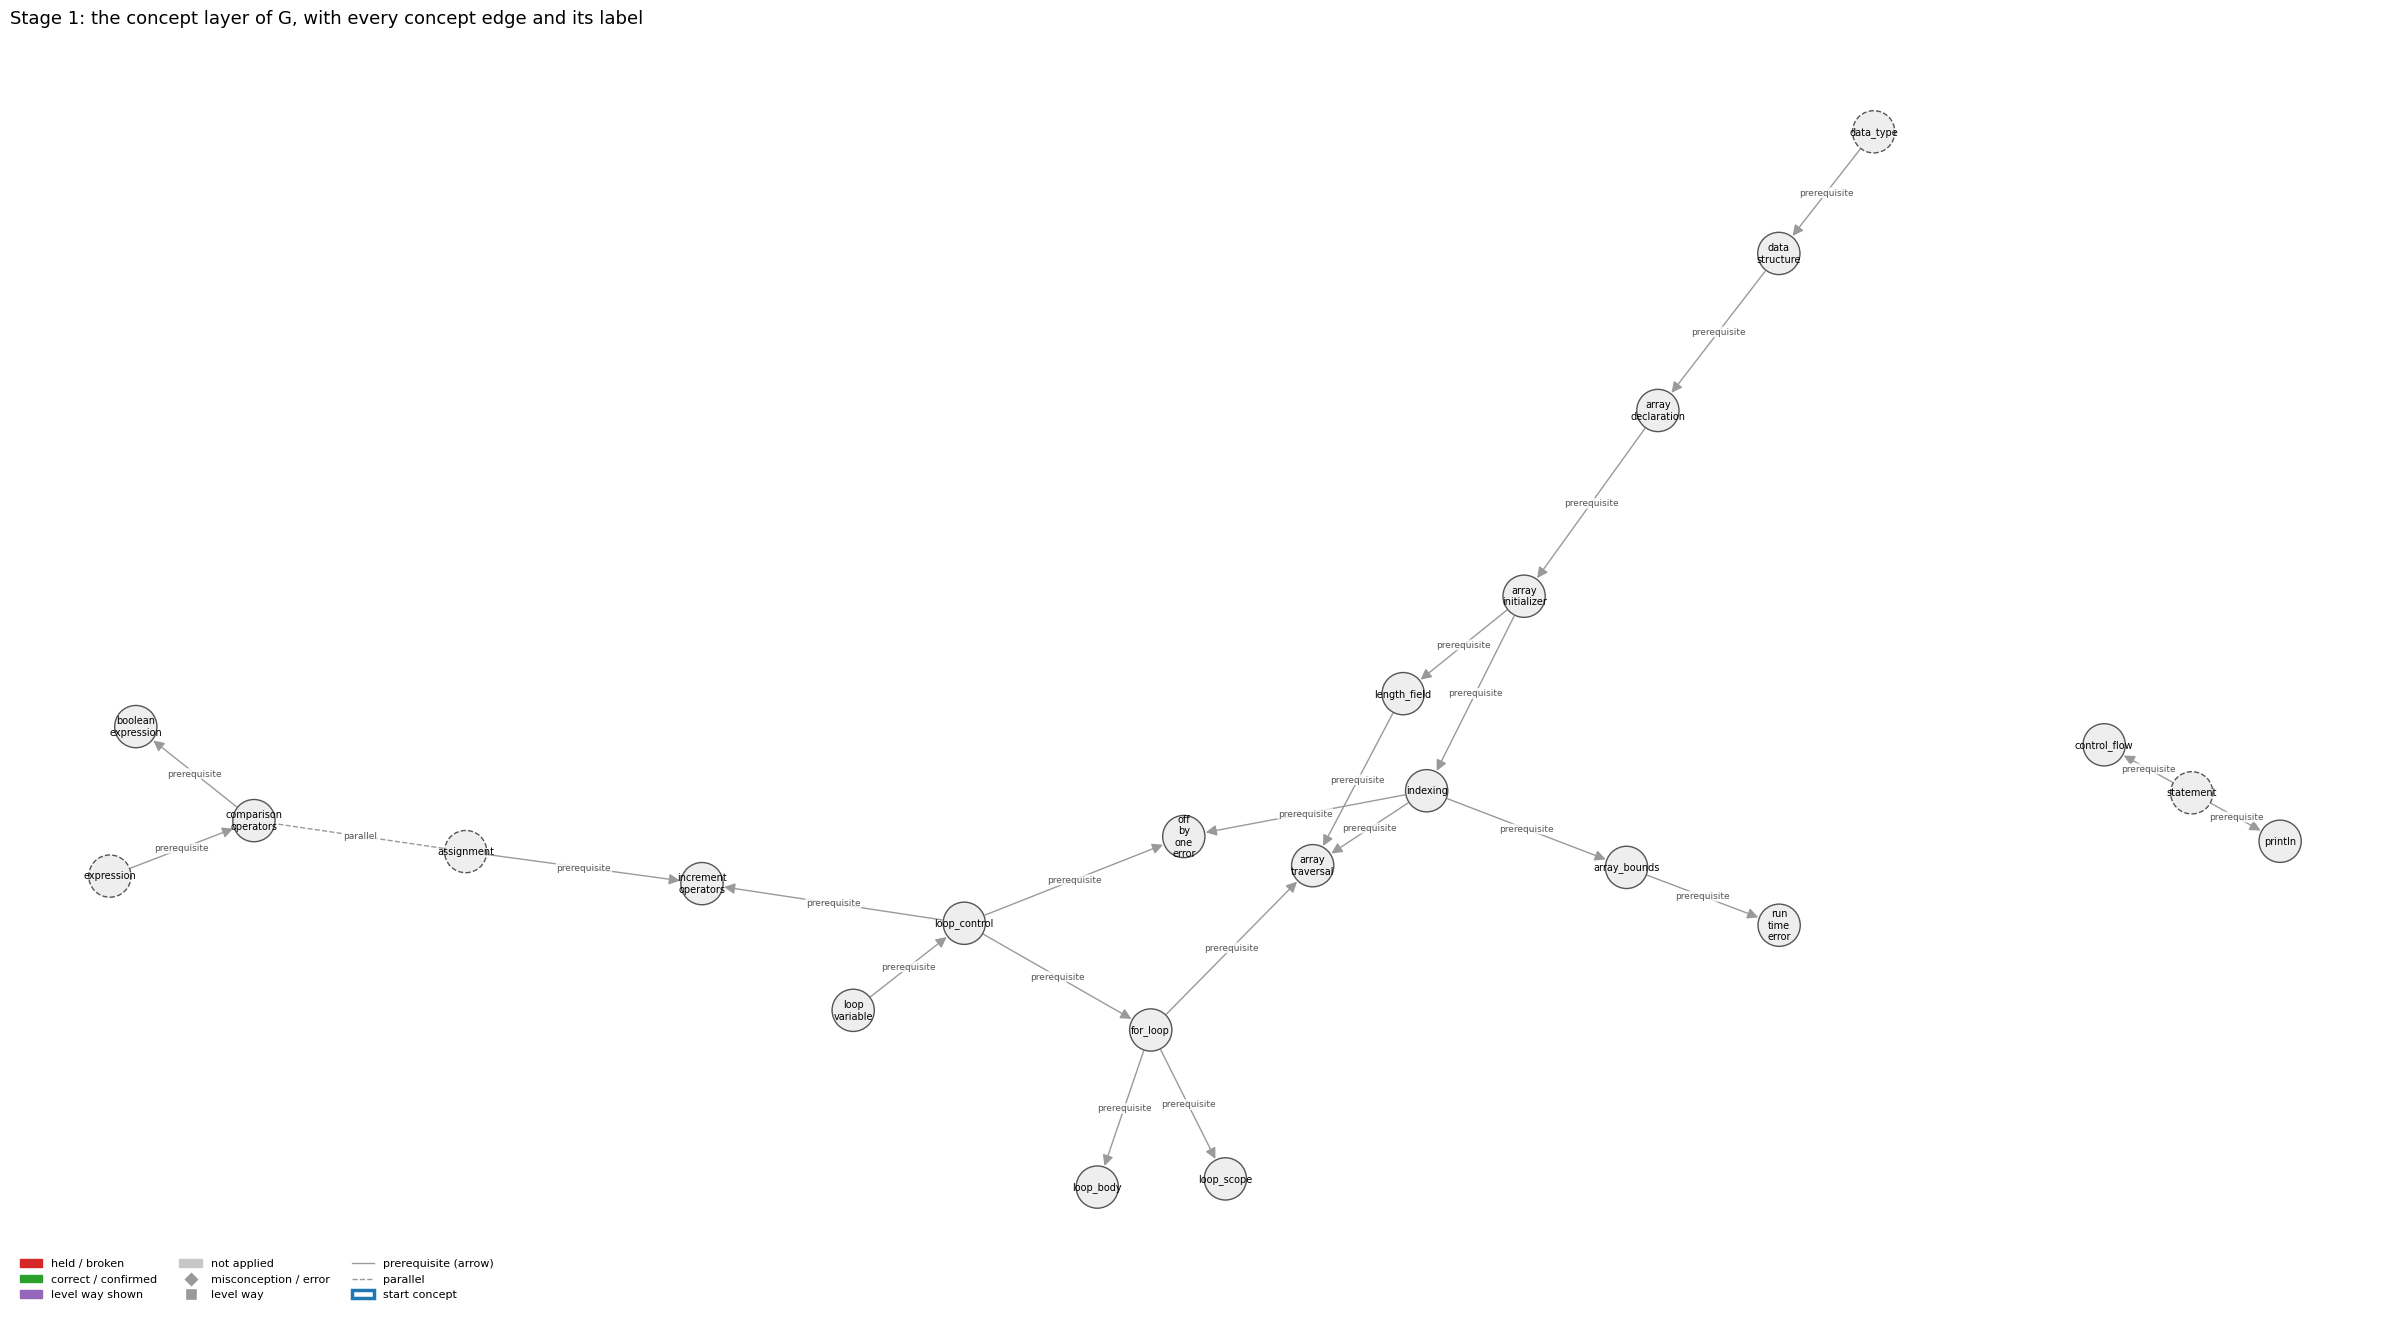

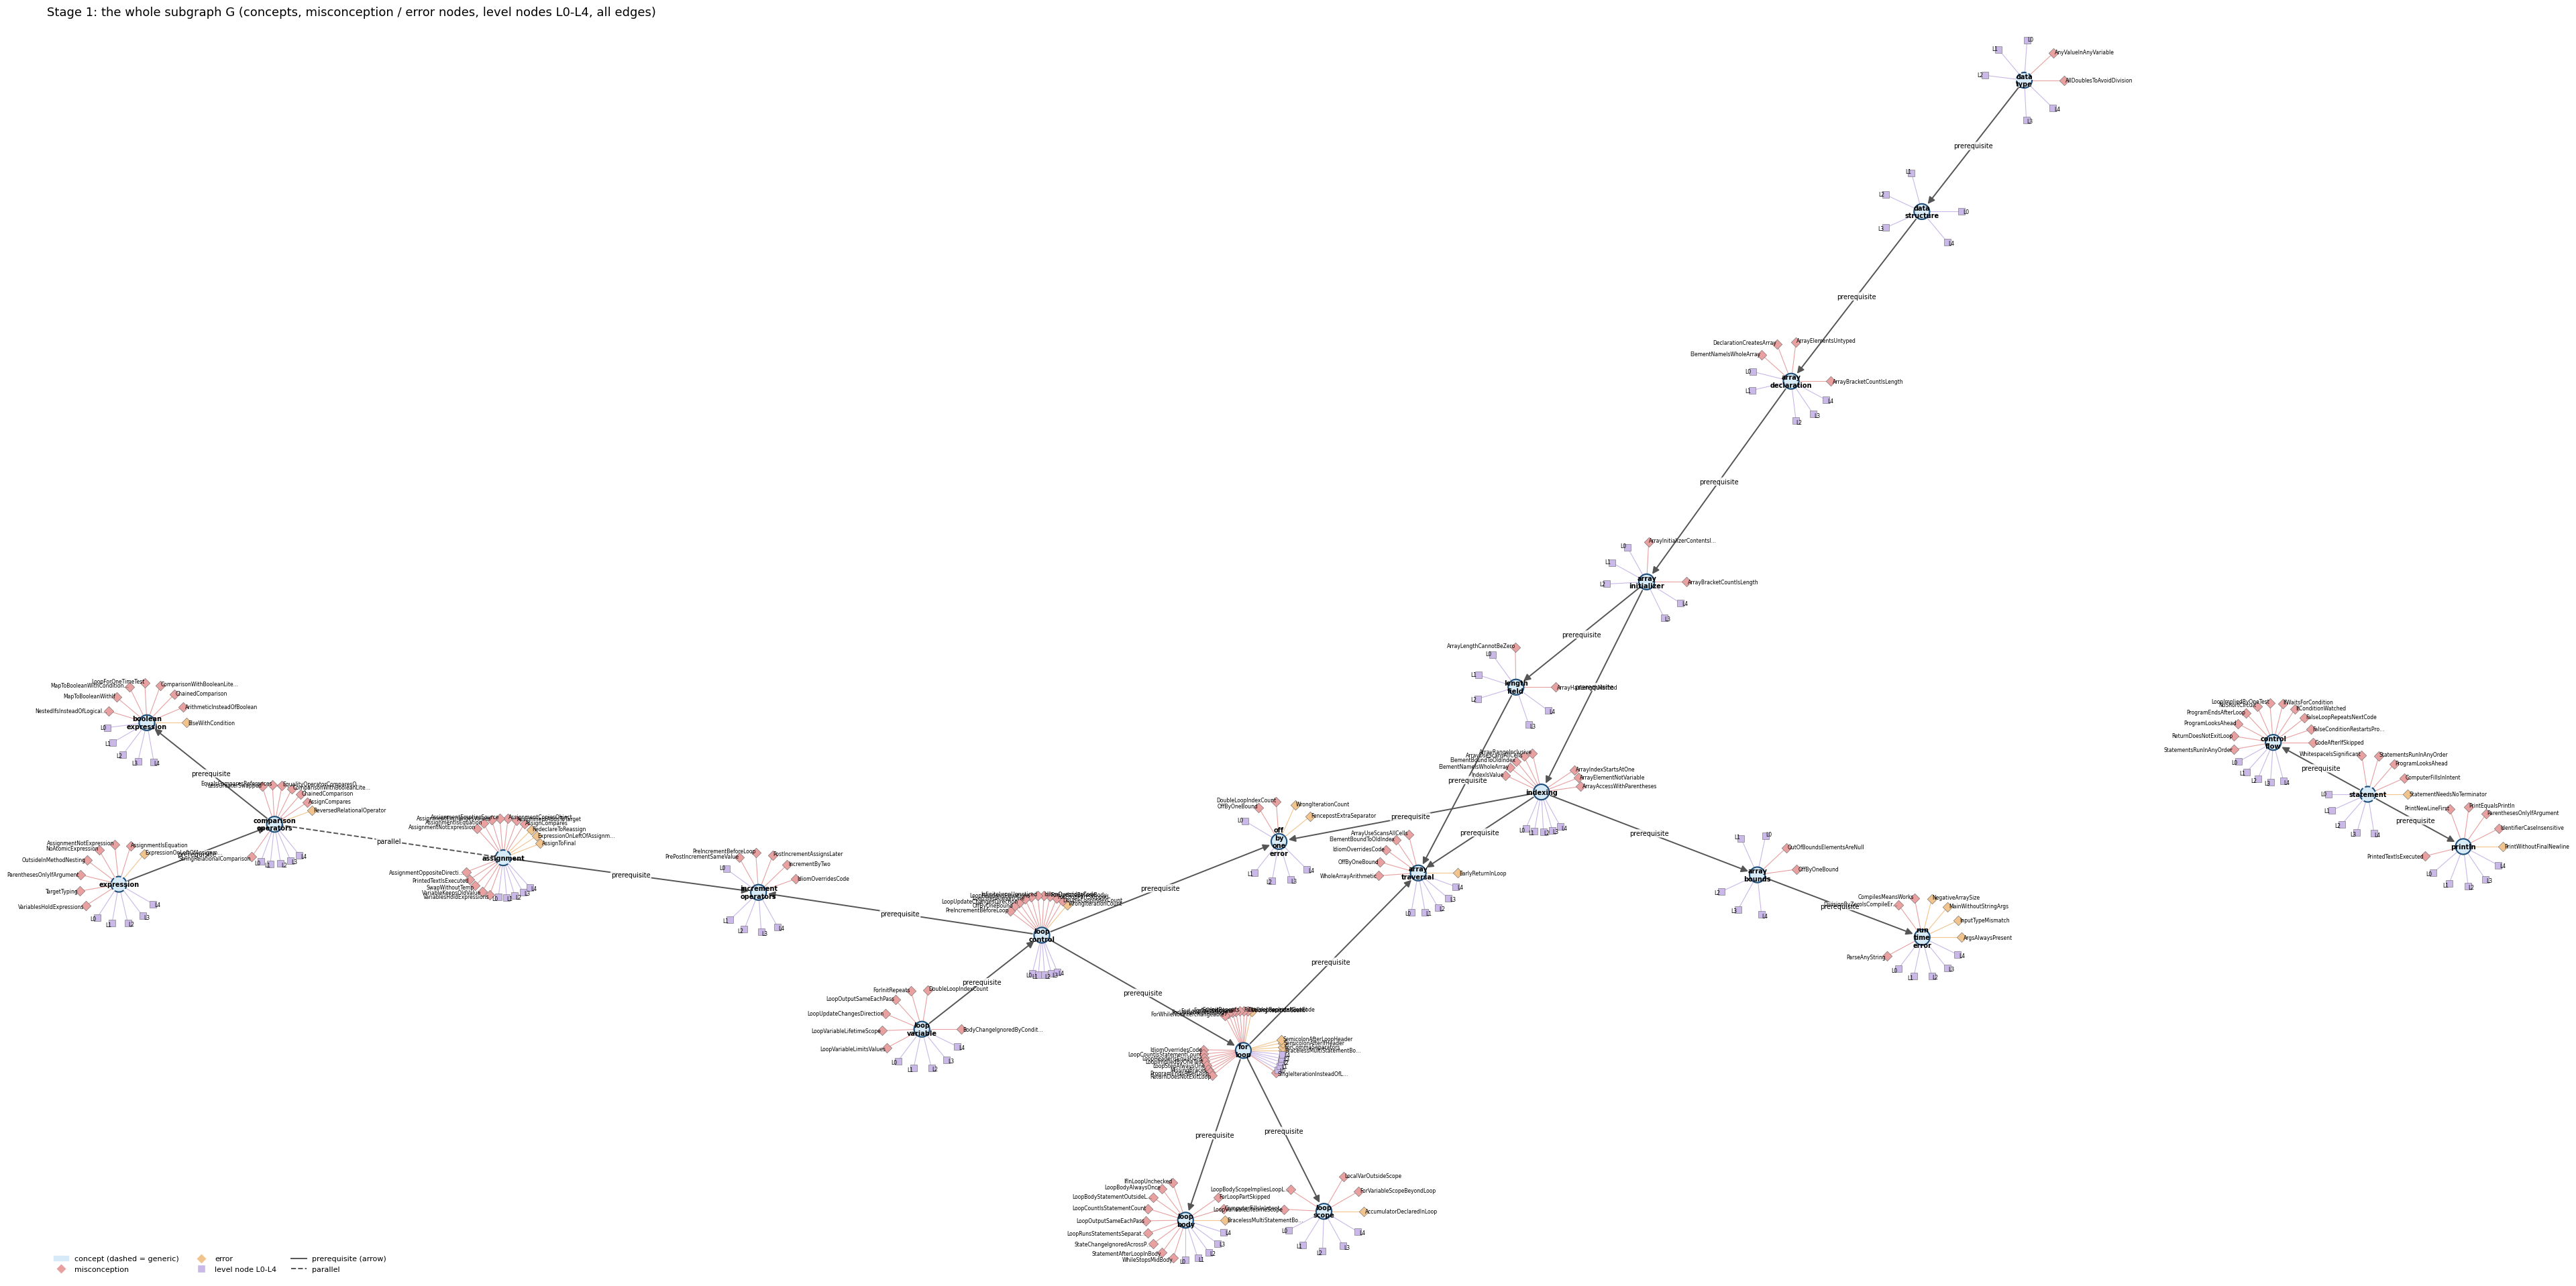

**Interactive view of G** (zoom and drag; hover an edge to read its rule):

## Step 2. Stage 2, exactly as `python src/traverse.py`: the Claude CLI walks G reading the student's answer

running: backend claude-cli, model claude-opus-5-5, prune llm, width 3, depth 3 ...


  prune array_traversal                               cached


  label array_traversal                               cached


  prune array_traversal                               cached


... (58 outputs left out)

## Step 3. Clauses and start concepts (no model)

**Clauses** (the answer split by rule):

,clause,text
0,c1,i goes from 0 to a.length
1,c2,Using <= or < makes no difference here
2,c3,because both go through the whole array
3,c4,so it visits each element once


start: generic concepts whose tagging text occurs in the answer: assignment
start: BM25 of the answer against each tagged concept: array_traversal 22.33 (hits 2), loop_control 17.93 (hits 1), for_loop 15.39 (hits 1), indexing 14.08 (hits 1), off_by_one_error 13.89 (hits 1), increment_operators 12.70 (hits 1), control_flow 11.84 (hits 1), array_declaration 11.75 (hits 1), array_bounds 11.65 (hits 1), array_initializer 11.22 (hits 1), length_field 11.12 (hits 1), boolean_expression 10.87 (hits 1), loop_variable 9.71 (hits 1), assignment 9.31 (hits 1), loop_body 8.10 (hits 1), comparison_operators 7.00 (hits 1), loop_scope 5.79 (hits 1), run_time_error 4.52 (hits 1), println 3.84 (hits 1), data_structure 1.63 (hits 1)
start: chosen array_traversal, loop_control, for_loop
start concepts (3): array_traversal, loop_control, for_loop


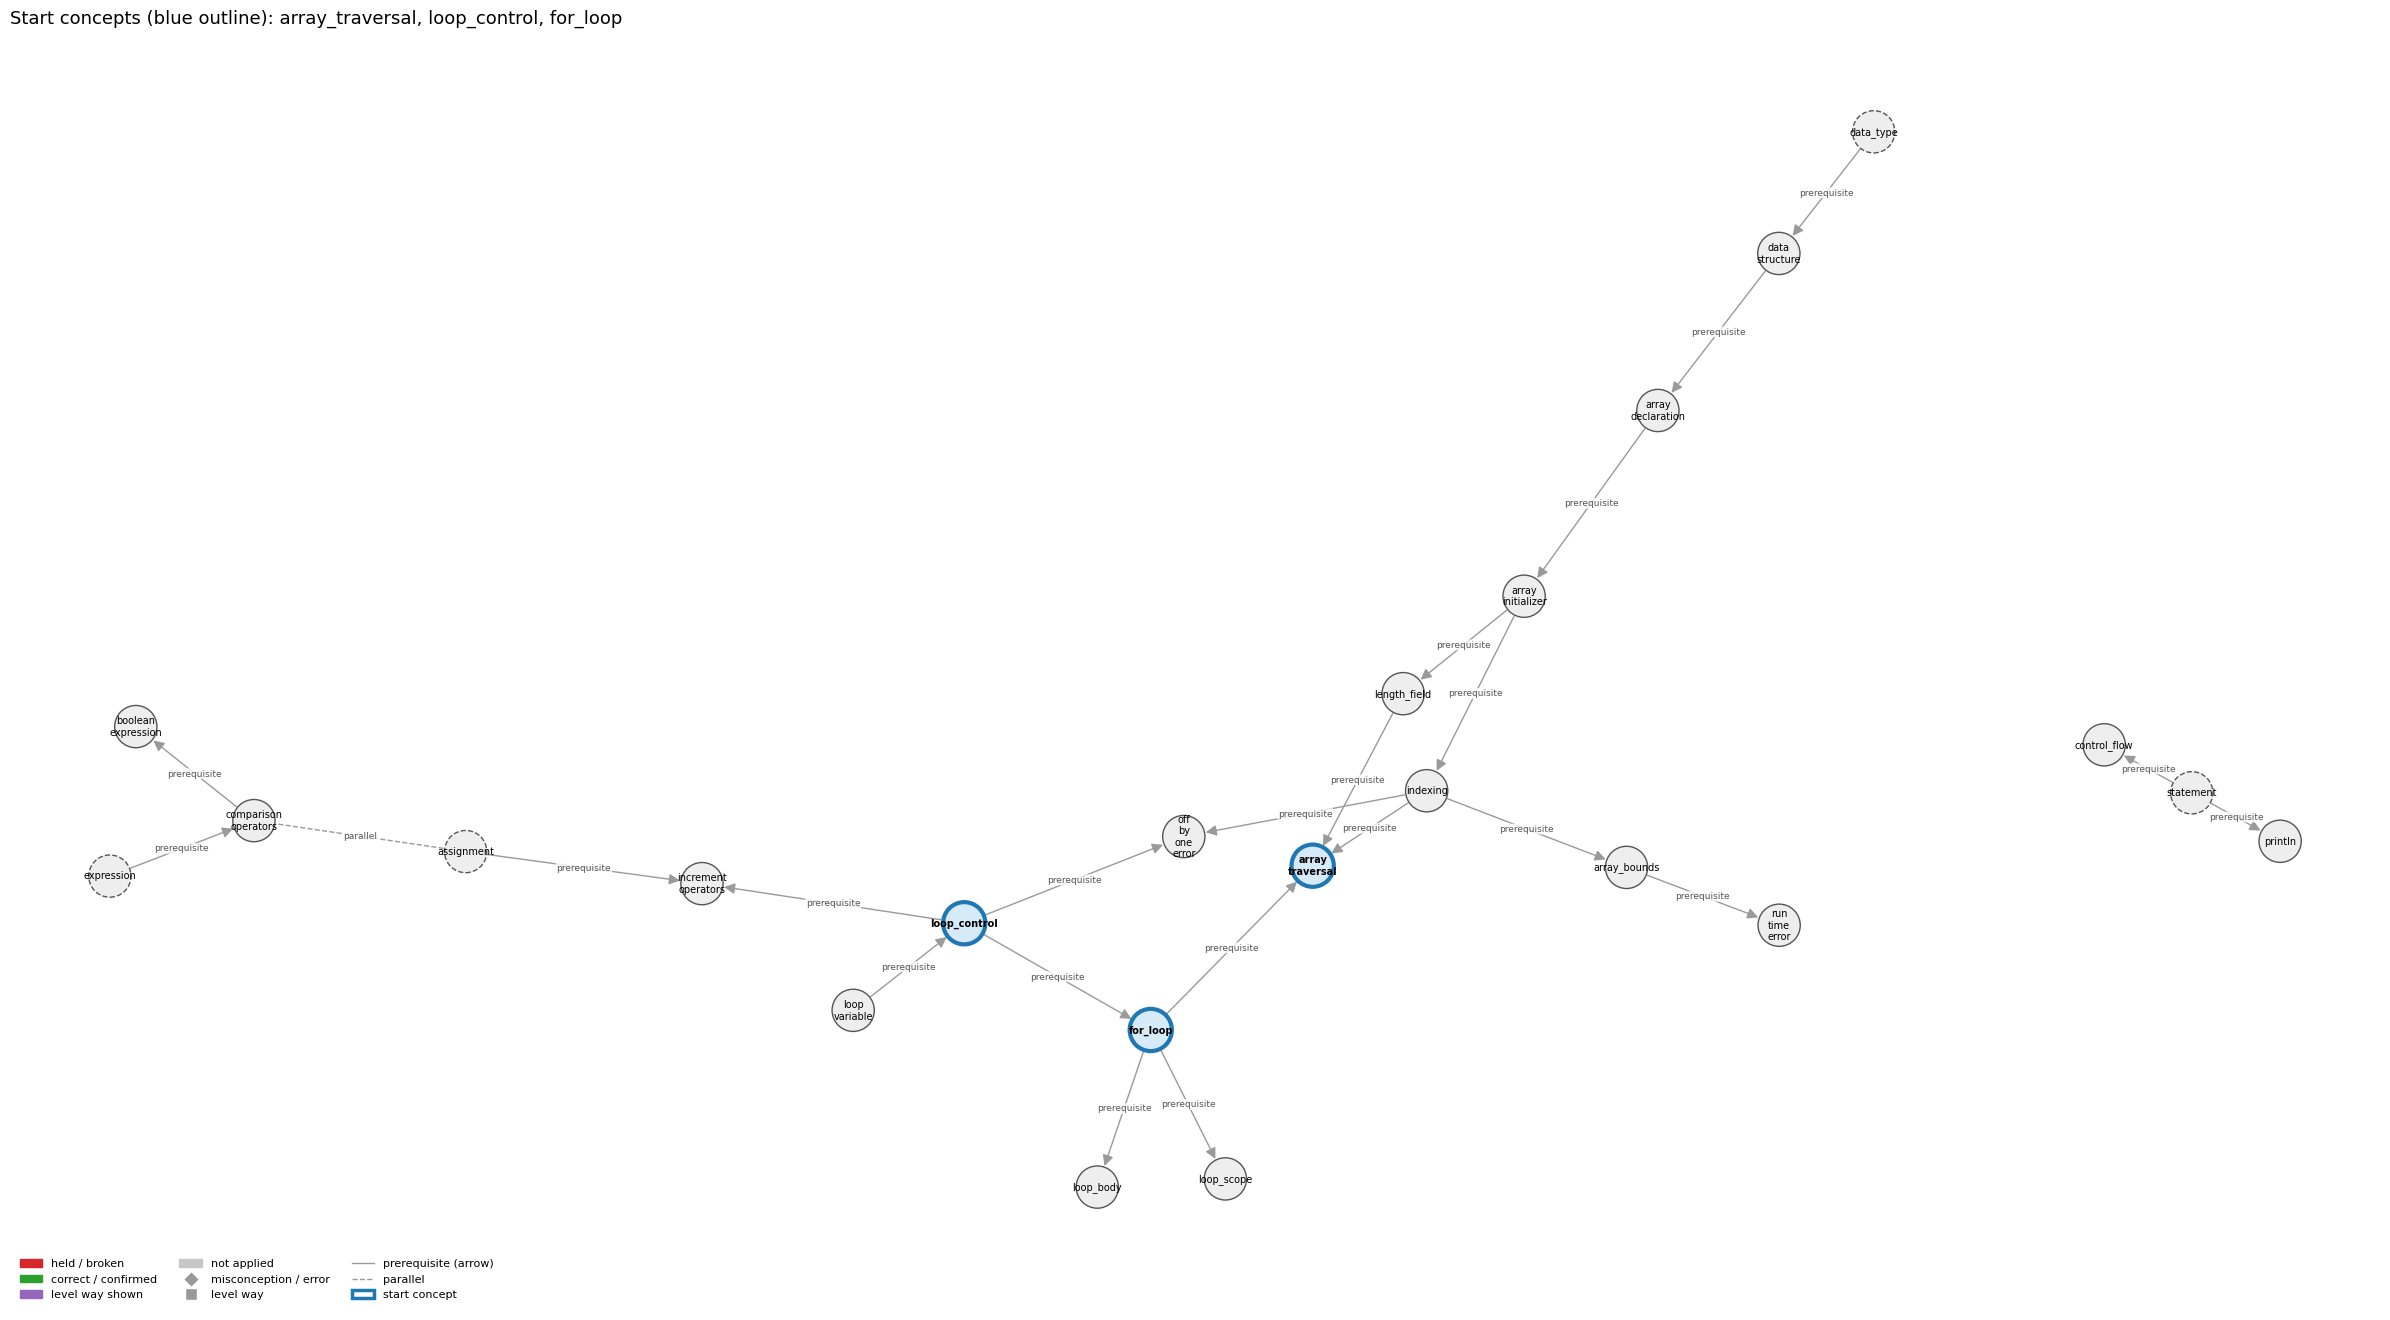

## Step 4. The walk, depth by depth

---
#### Depth 1: current concepts array_traversal, loop_control, for_loop

**Edge search and pruning**

,concept,edge family,candidates offered,kept by pruning
0,array_traversal,misconceptions,6,"mis:array_traversal->OffByOneBound (0.60), mis..."
1,array_traversal,level ways,22,"lvl:array_traversal@L0#0 (0.50), lvl:array_tra..."
2,loop_control,misconceptions,11,"mis:loop_control->OffByOneBound (0.60), mis:lo..."
3,loop_control,level ways,19,"lvl:loop_control@L4#0 (0.45), lvl:loop_control..."
4,for_loop,misconceptions,21,"mis:for_loop->IdiomOverridesCode (0.60), err:f..."
5,for_loop,level ways,24,"lvl:for_loop@L4#5 (0.40), lvl:for_loop@L4#0 (0..."


**Labels from the model** (score = prune score x confidence)

,edge,label,score,clauses,kept on a path
0,mis:array_traversal->OffByOneBound,held,0.570000,i goes from 0 to a.length; Using <= or < makes no difference here; because both go through the whole array; so it visits each element once,yes
1,mis:array_traversal->IdiomOverridesCode,not applied,0.000000,,
2,mis:array_traversal->ArrayUseScansAllCells,not applied,0.000000,,
3,lvl:array_traversal@L0#0,shown,0.450000,Using <= or < makes no difference here; because both go through the whole array; so it visits each element once,
4,lvl:array_traversal@L4#3,not applied,0.000000,,
5,lvl:array_traversal@L3#2,not applied,0.000000,,
6,mis:loop_control->OffByOneBound,held,0.550000,i goes from 0 to a.length; Using <= or < makes no difference here; because both go through the whole array,yes
7,mis:loop_control->IdiomOverridesCode,held,0.190000,because both go through the whole array; so it visits each element once,yes
8,err:loop_control->WrongIterationCount,not applied,0.000000,,
9,lvl:loop_control@L4#0,not applied,0.000000,,


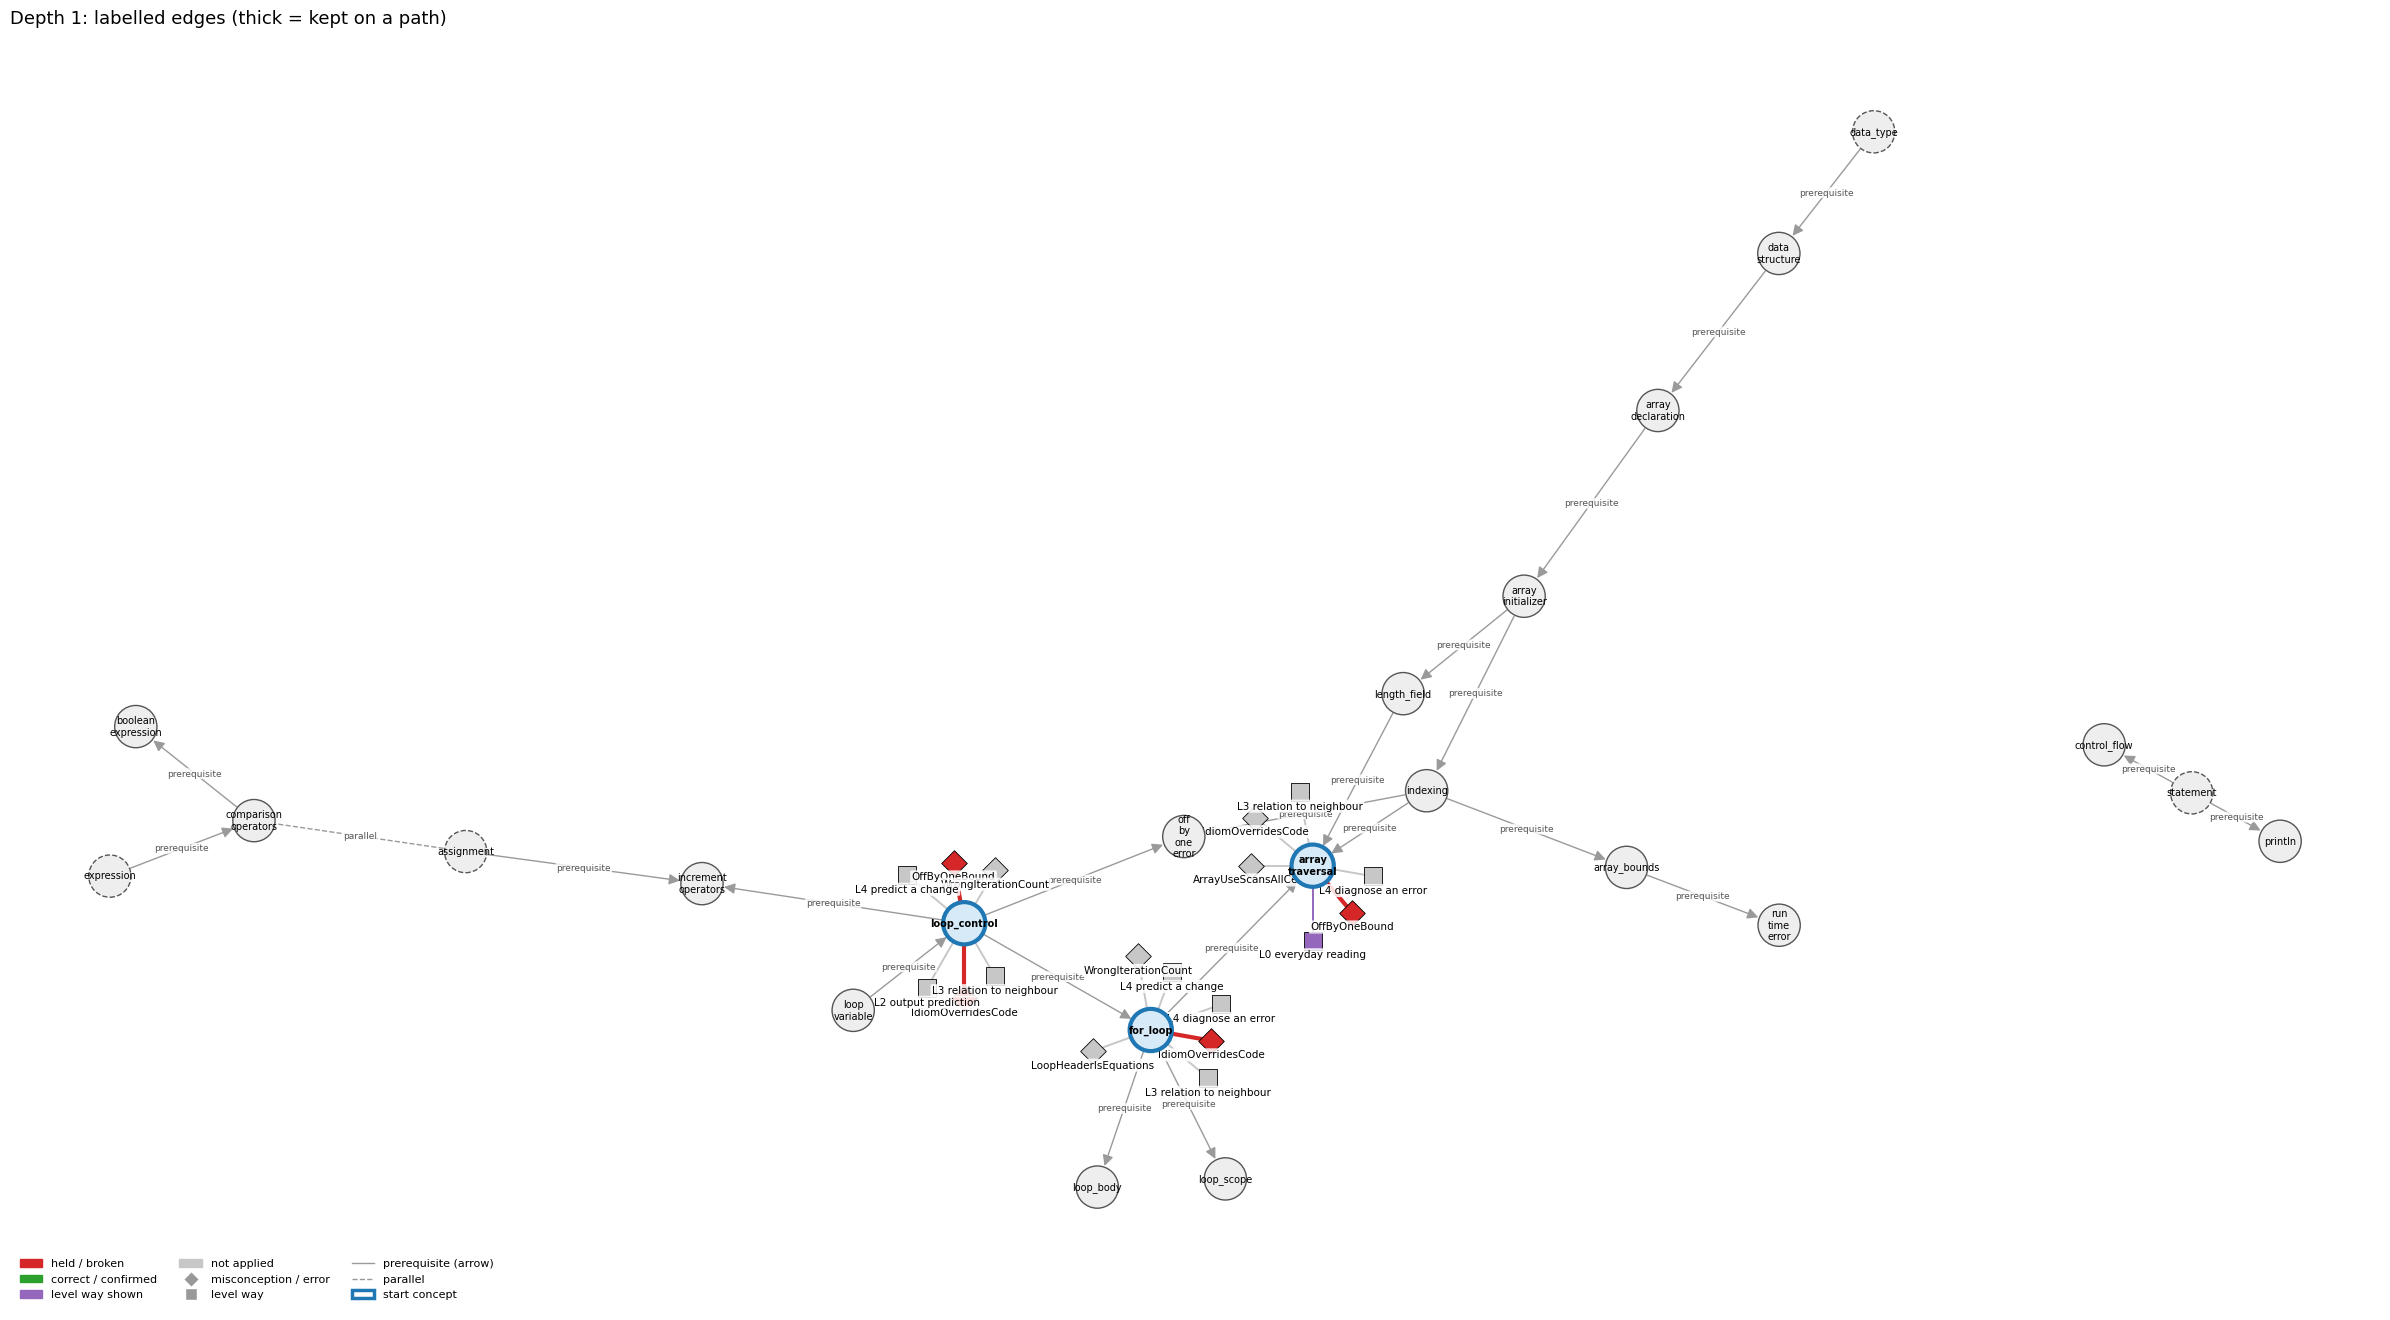

**Clause coverage after this depth**

,clause,text,covered by
0,c1,i goes from 0 to a.length,mis:array_traversal->OffByOneBound
1,c2,Using <= or < makes no difference here,mis:array_traversal->OffByOneBound
2,c3,because both go through the whole array,mis:array_traversal->OffByOneBound
3,c4,so it visits each element once,mis:array_traversal->OffByOneBound


graph check, not yet read: pre:for_loop->array_traversal, pre:for_loop->loop_body, pre:for_loop->loop_scope, pre:indexing->array_traversal, pre:length_field->array_traversal, pre:loop_control->for_loop, pre:loop_control->increment_operators, pre:loop_control->off_by_one_error, pre:loop_variable->loop_control


---
#### Depth 2: current concepts array_traversal, loop_control, for_loop

**Edge search and pruning**

,concept,edge family,candidates offered,kept by pruning
0,array_traversal,concept edges,3,"pre:length_field->array_traversal (0.50), pre:..."
1,loop_control,concept edges,4,"pre:loop_control->off_by_one_error (0.60), pre..."
2,for_loop,concept edges,2,"pre:for_loop->loop_body (0.80), pre:for_loop->..."


**Labels from the model** (score = prune score x confidence)

,edge,label,score,clauses,kept on a path
0,pre:length_field->array_traversal,broken,0.470000,i goes from 0 to a.length; Using <= or < makes no difference here; because both go through the whole array,yes
1,pre:for_loop->array_traversal,broken,0.370000,i goes from 0 to a.length; Using <= or < makes no difference here; because both go through the whole array,yes
2,pre:indexing->array_traversal,confirmed,0.060000,i goes from 0 to a.length; so it visits each element once,
3,pre:loop_control->off_by_one_error,broken,0.550000,Using <= or < makes no difference here; because both go through the whole array; so it visits each element once,yes
4,pre:loop_variable->loop_control,broken,0.190000,Using <= or < makes no difference here; because both go through the whole array,yes
5,pre:loop_control->for_loop,broken,0.110000,Using <= or < makes no difference here; because both go through the whole array; so it visits each element once,yes
6,pre:for_loop->loop_body,not applied,0.000000,,
7,pre:for_loop->loop_scope,not applied,0.000000,,


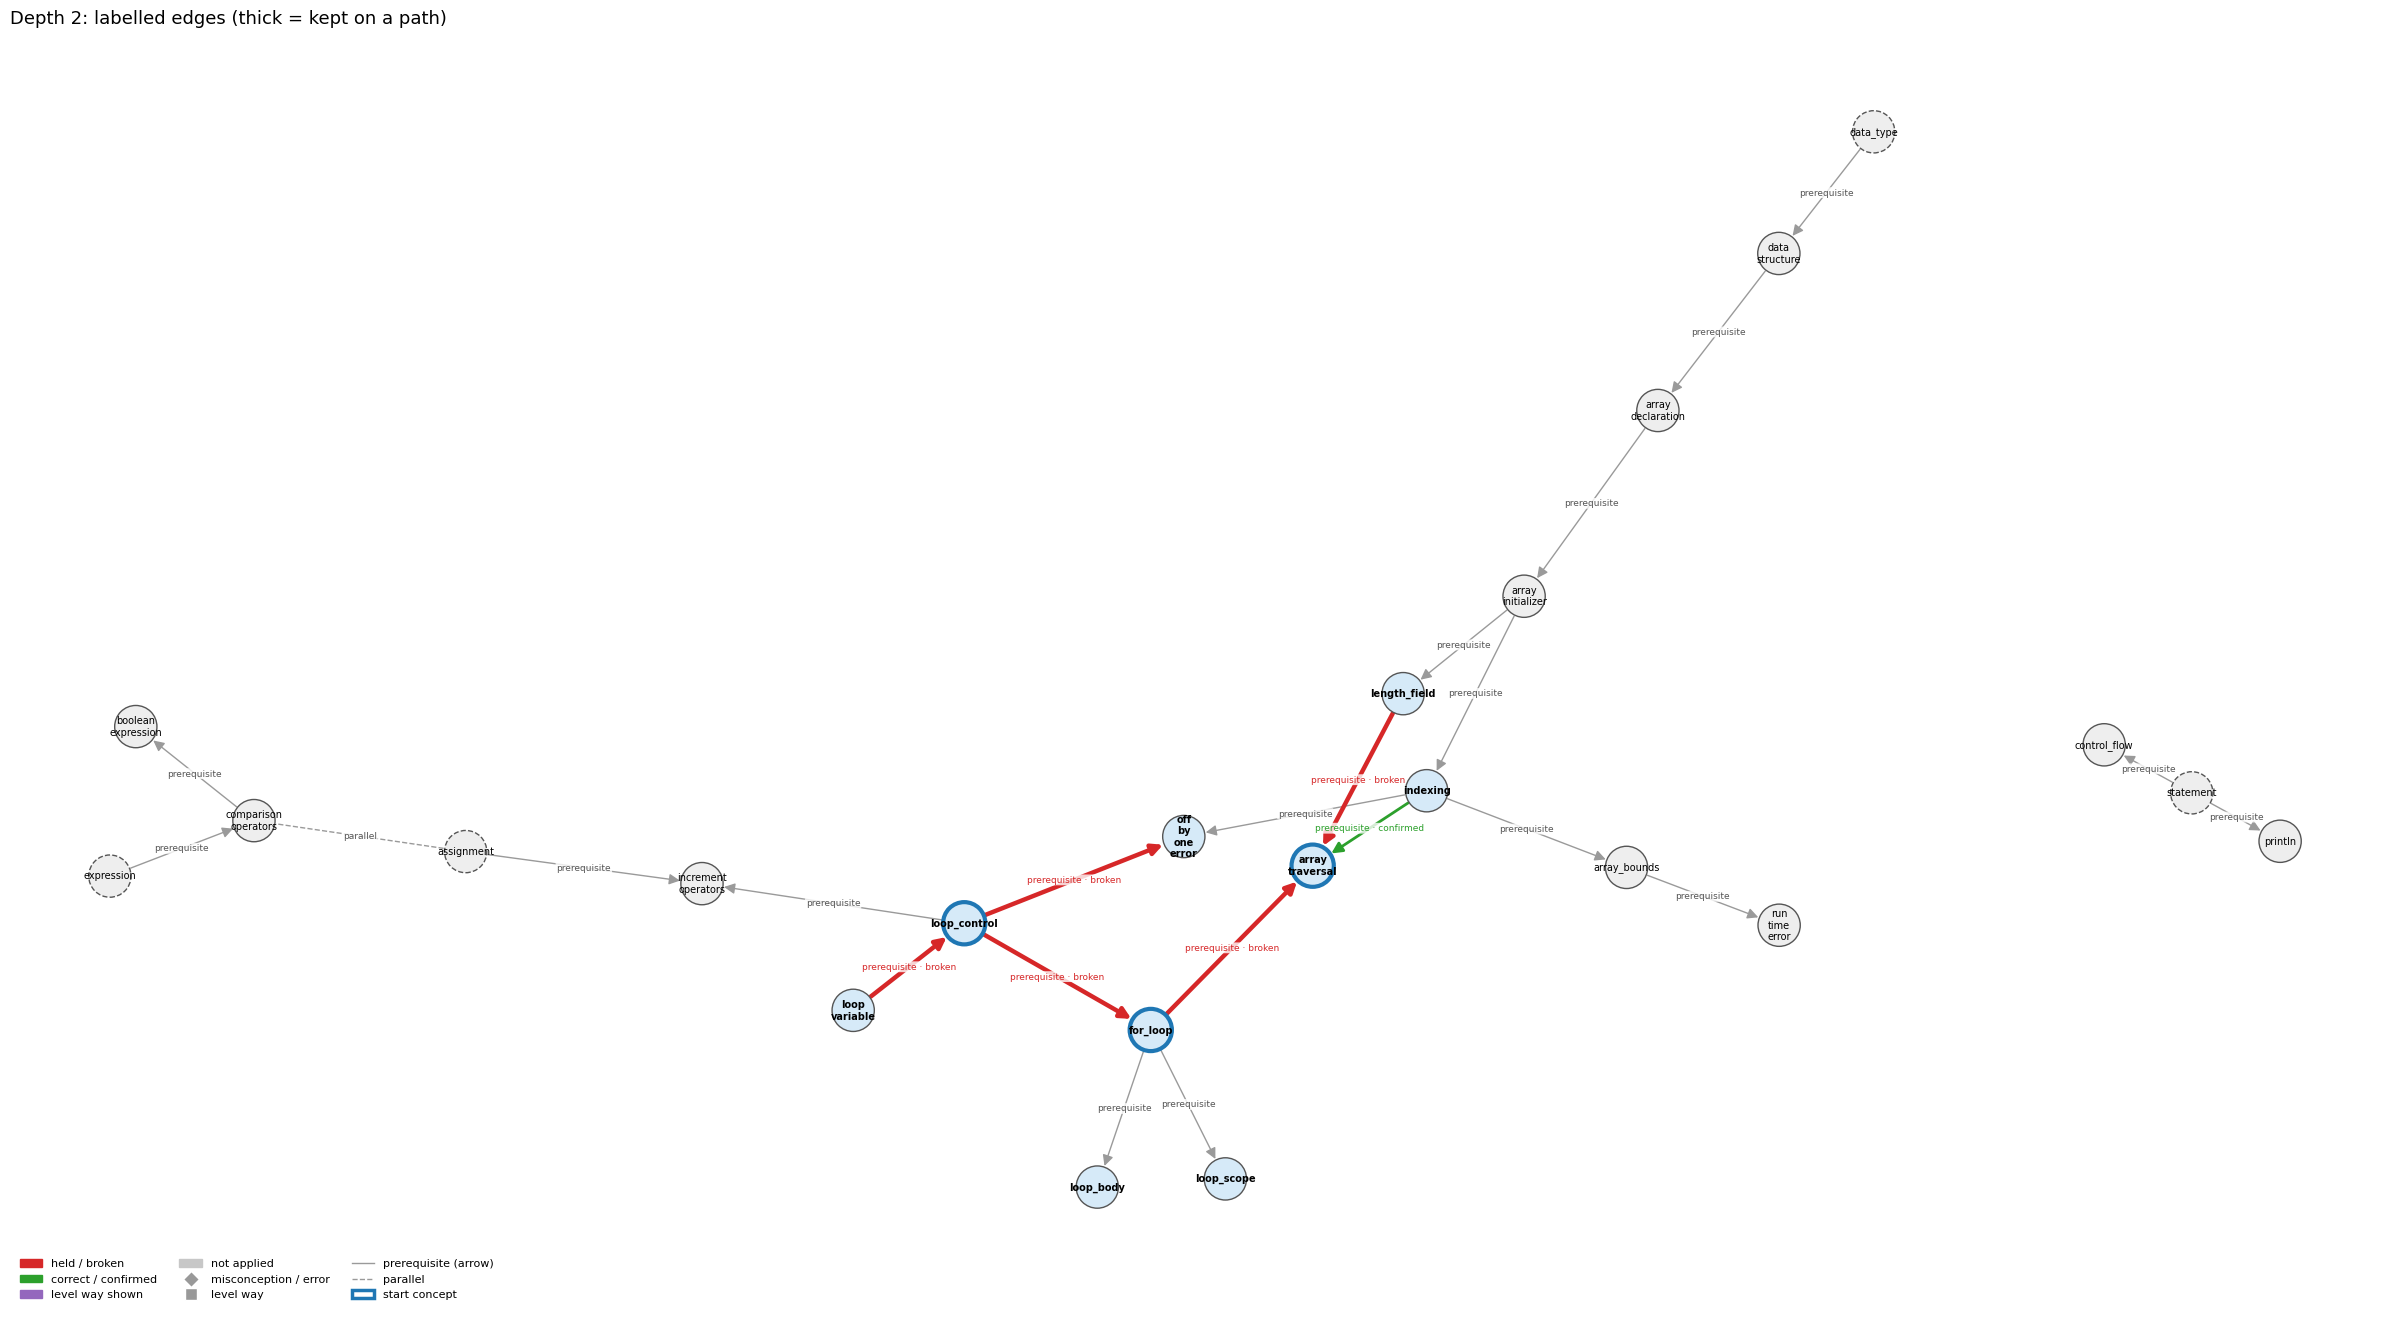

**Clause coverage after this depth**

,clause,text,covered by
0,c1,i goes from 0 to a.length,mis:array_traversal->OffByOneBound
1,c2,Using <= or < makes no difference here,mis:array_traversal->OffByOneBound
2,c3,because both go through the whole array,mis:array_traversal->OffByOneBound
3,c4,so it visits each element once,mis:array_traversal->OffByOneBound


graph check, not yet read: own edges of length_field, own edges of loop_variable, own edges of off_by_one_error


---
#### Depth 3: current concepts off_by_one_error, loop_control, length_field, array_traversal, for_loop, loop_variable

**Edge search and pruning**

,concept,edge family,candidates offered,kept by pruning
0,off_by_one_error,misconceptions,4,"mis:off_by_one_error->OffByOneBound (0.75), er..."
1,off_by_one_error,level ways,16,"lvl:off_by_one_error@L0#2 (0.50), lvl:off_by_o..."
2,loop_control,concept edges,1,pre:loop_control->increment_operators (1.00)
3,length_field,misconceptions,2,"mis:length_field->ArrayHasLengthMethod (0.90),..."
4,length_field,level ways,15,"lvl:length_field@L0#2 (0.45), lvl:length_field..."
5,array_traversal,concept edges,1,pre:indexing->array_traversal (1.00)
6,for_loop,concept edges,2,"pre:for_loop->loop_body (0.80), pre:for_loop->..."
7,loop_variable,misconceptions,7,mis:loop_variable->LoopOutputSameEachPass (0.4...
8,loop_variable,level ways,13,"lvl:loop_variable@L2#1 (0.45), lvl:loop_variab..."


**Labels from the model** (score = prune score x confidence)

,edge,label,score,clauses,kept on a path
0,mis:off_by_one_error->OffByOneBound,held,0.710000,i goes from 0 to a.length; Using <= or < makes no difference here; because both go through the whole array; so it visits each element once,yes
1,err:off_by_one_error->WrongIterationCount,not applied,0.000000,,
2,err:off_by_one_error->FencepostExtraSeparator,not applied,0.000000,,
3,lvl:off_by_one_error@L0#2,shown,0.350000,Using <= or < makes no difference here; because both go through the whole array,yes
4,lvl:off_by_one_error@L4#0,not applied,0.000000,,
5,lvl:off_by_one_error@L0#0,shown,0.170000,i goes from 0 to a.length; Using <= or < makes no difference here; because both go through the whole array,
6,pre:loop_control->increment_operators,not applied,0.000000,,
7,mis:length_field->ArrayHasLengthMethod,not applied,0.000000,,
8,mis:length_field->ArrayLengthCannotBeZero,not applied,0.000000,,
9,lvl:length_field@L0#2,shown,0.320000,i goes from 0 to a.length; Using <= or < makes no difference here; because both go through the whole array,


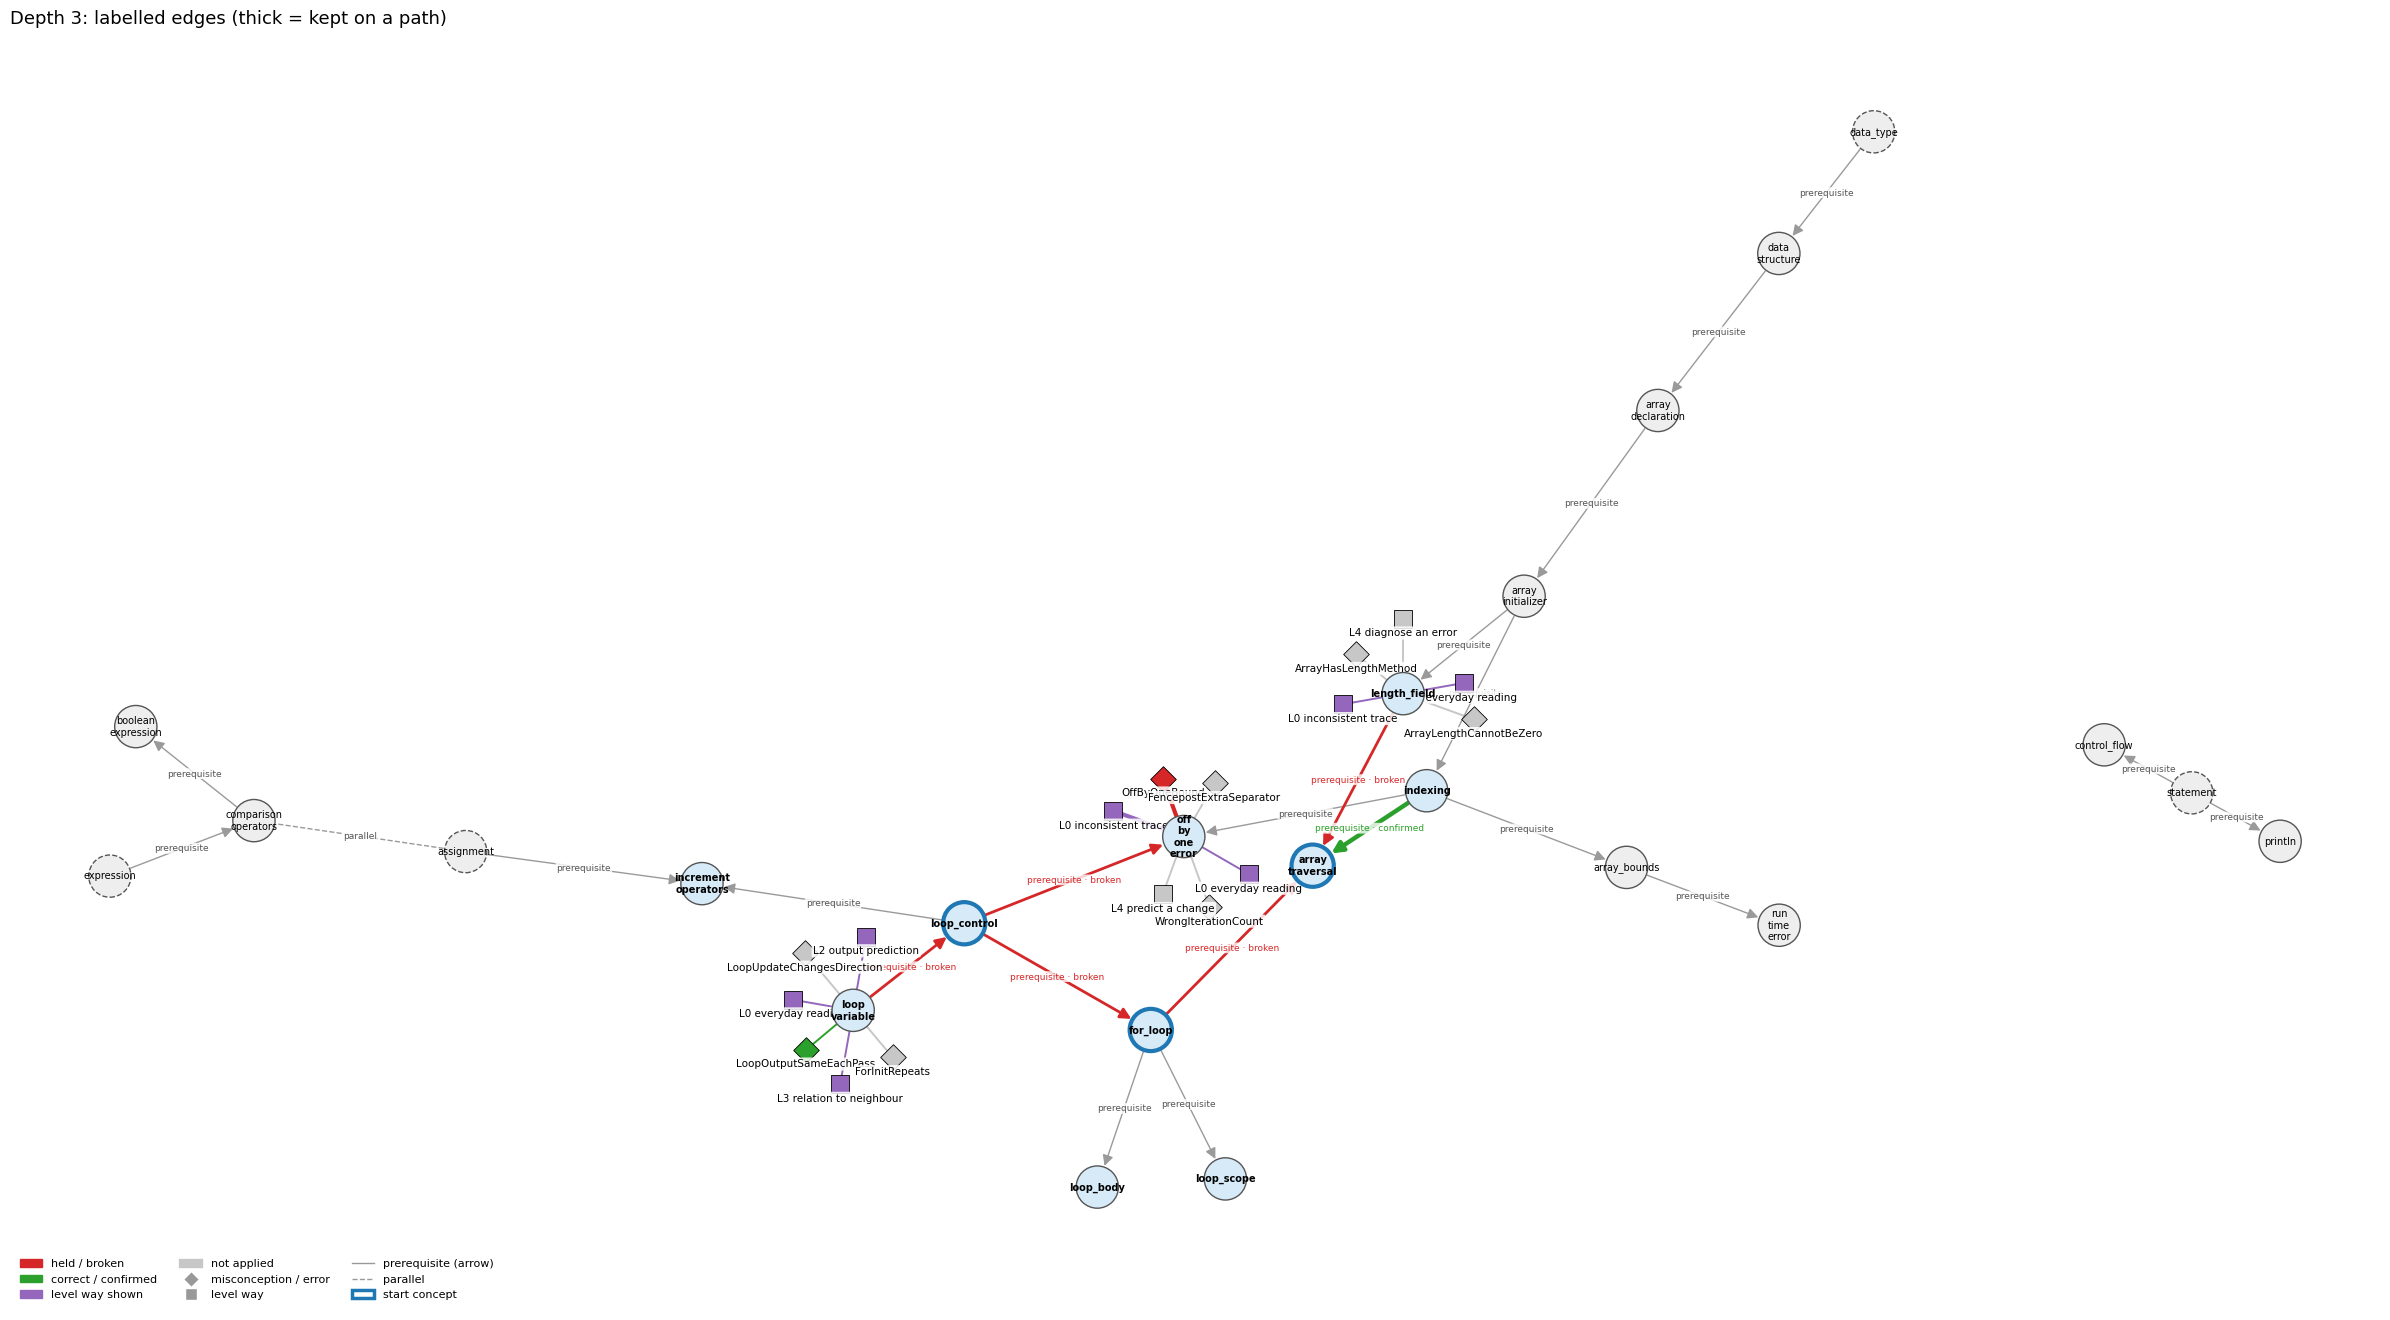

**Clause coverage after this depth**

,clause,text,covered by
0,c1,i goes from 0 to a.length,mis:array_traversal->OffByOneBound
1,c2,Using <= or < makes no difference here,mis:array_traversal->OffByOneBound
2,c3,because both go through the whole array,mis:array_traversal->OffByOneBound
3,c4,so it visits each element once,mis:array_traversal->OffByOneBound


graph check, not yet read: own edges of indexing, pre:array_initializer->length_field, pre:indexing->off_by_one_error


---
#### Depth 4: current concepts indexing

**Edge search and pruning**

,concept,edge family,candidates offered,kept by pruning
0,indexing,misconceptions,8,"mis:indexing->ArrayRangeInclusive (0.70), mis:..."
1,indexing,level ways,21,"lvl:indexing@L4#2 (0.40), lvl:indexing@L3#6 (0..."


**Labels from the model** (score = prune score x confidence)

,edge,label,score,clauses,kept on a path
0,mis:indexing->ArrayRangeInclusive,held,0.630000,i goes from 0 to a.length; Using <= or < makes no difference here; because both go through the whole array,yes
1,mis:indexing->ArrayIndexStartsAtOne,not applied,0.000000,,
2,mis:indexing->ArrayUseScansAllCells,not applied,0.000000,,
3,lvl:indexing@L4#2,not applied,0.000000,,
4,lvl:indexing@L3#6,not applied,0.000000,,
5,lvl:indexing@L1#1,not applied,0.000000,,


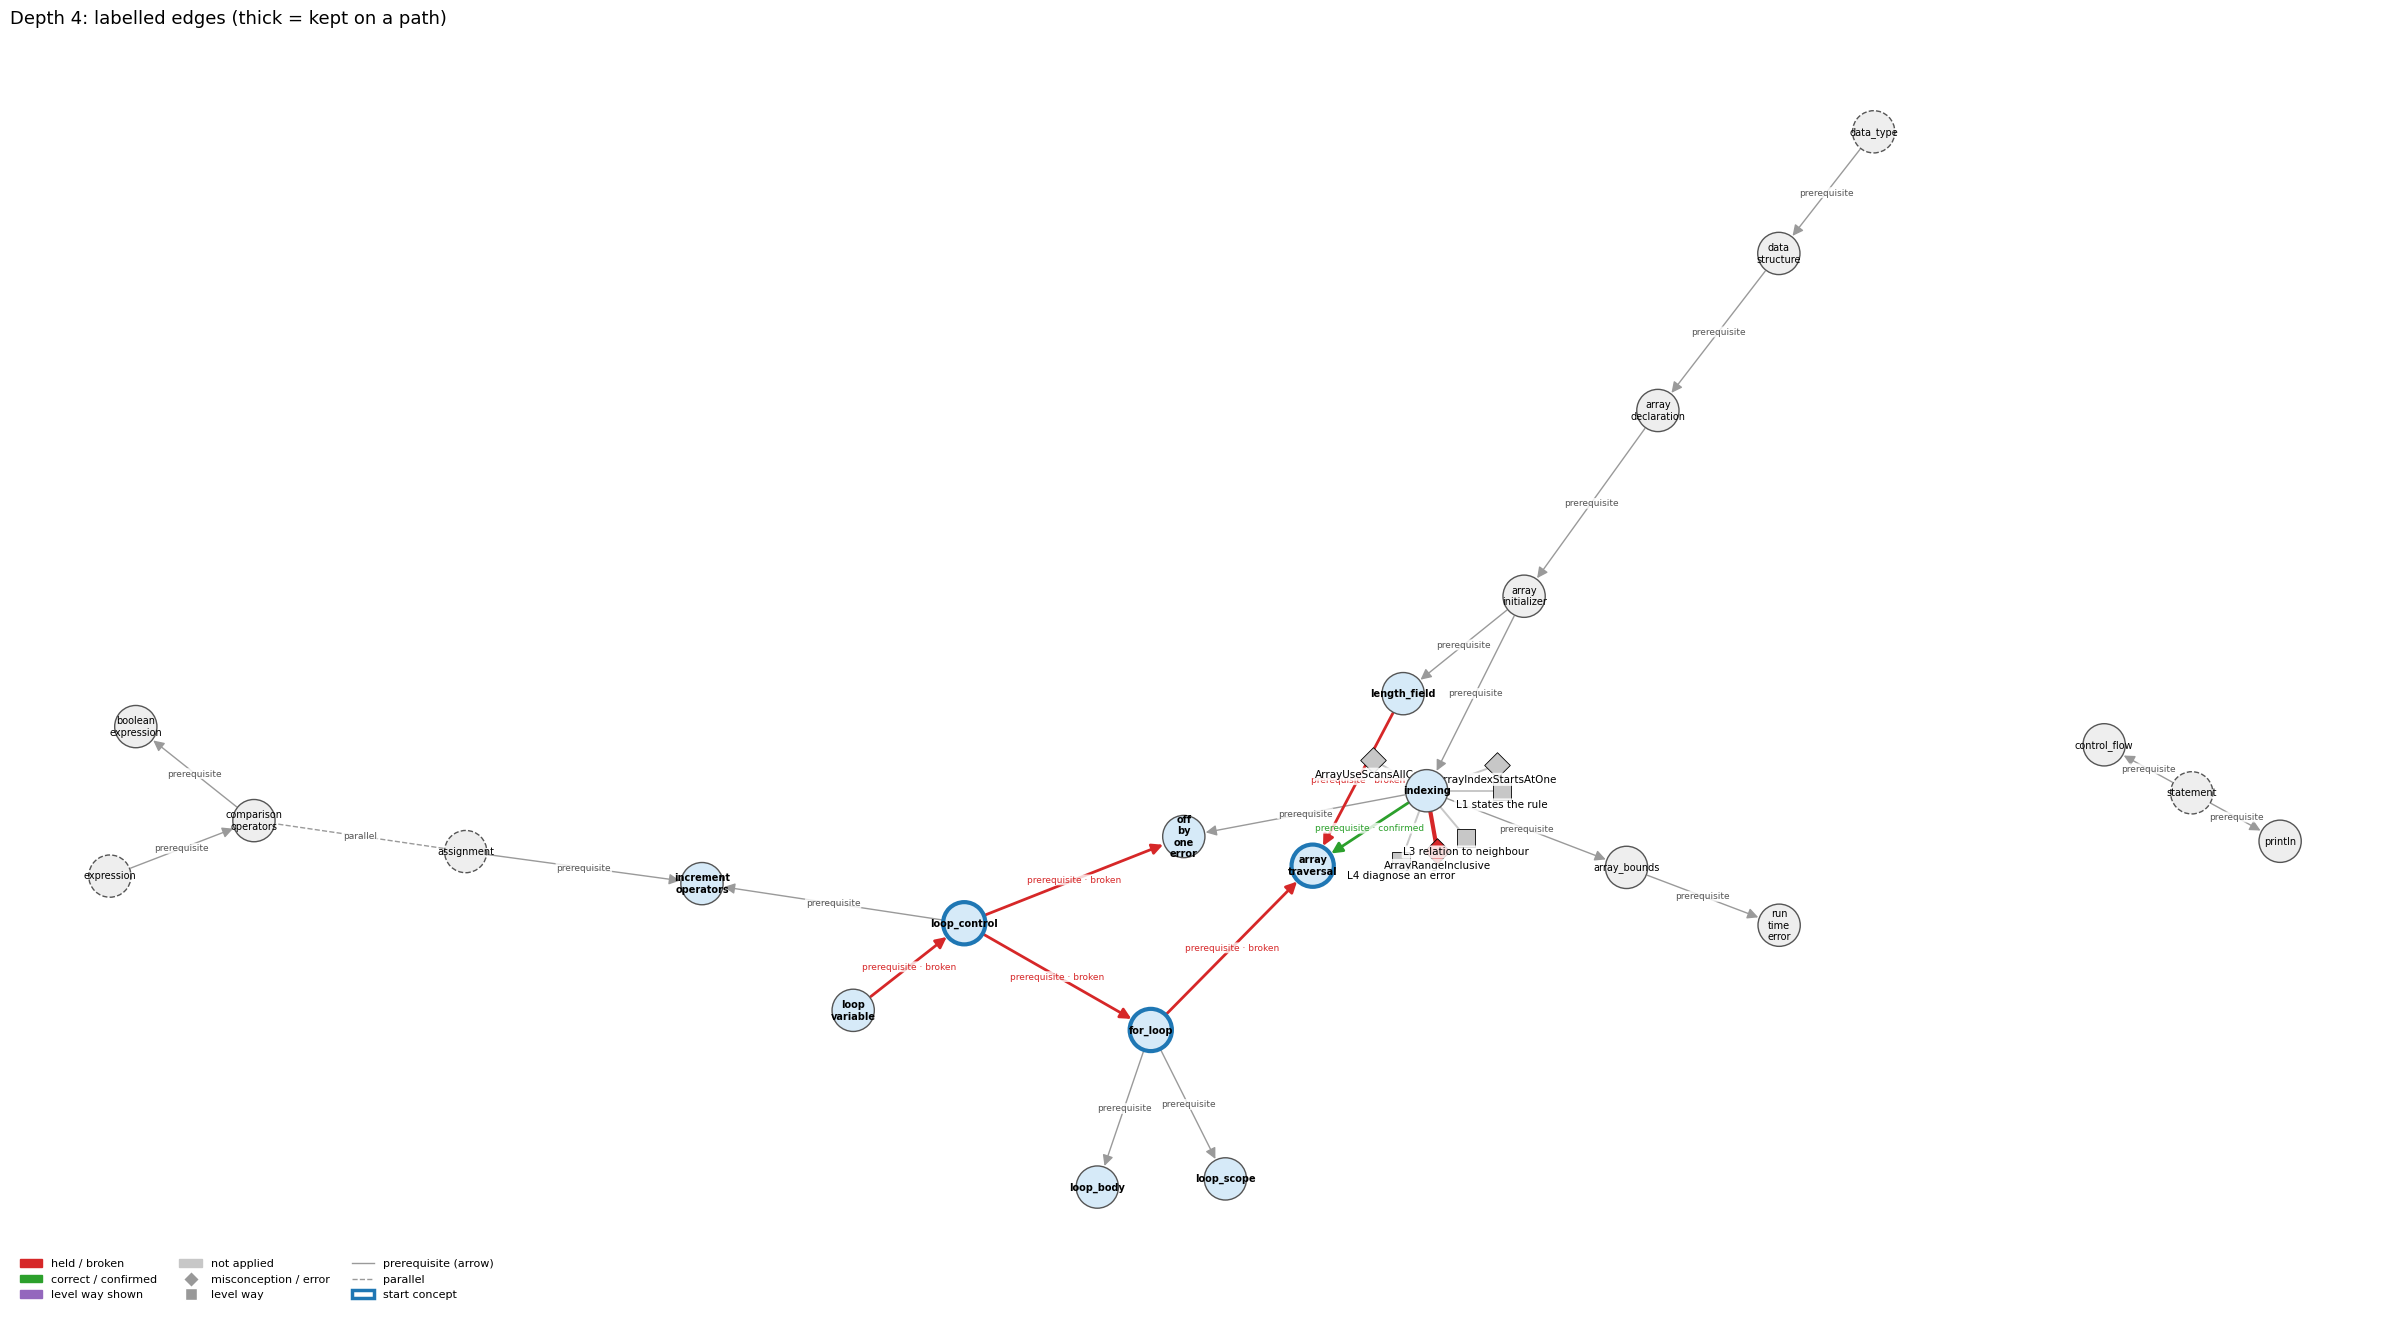

**Clause coverage after this depth**

,clause,text,covered by
0,c1,i goes from 0 to a.length,mis:array_traversal->OffByOneBound
1,c2,Using <= or < makes no difference here,mis:array_traversal->OffByOneBound
2,c3,because both go through the whole array,mis:array_traversal->OffByOneBound
3,c4,so it visits each element once,mis:array_traversal->OffByOneBound


graph check, not yet read: pre:array_initializer->indexing, pre:array_initializer->length_field, pre:indexing->array_bounds, pre:indexing->off_by_one_error


**Stop:** max depth at depth 4

## Step 5. Output: the diagnosis (rules over the labelled graph, no model)

**Held misconceptions**

... (5 outputs left out)

**Root cause:** off_by_one_error / OffByOneBound

**Level per concept**

,concept,level,way,source,evidence,note
0,array_traversal,L0,everyday_reading,level_way,Using <= or < makes no difference here; becaus...,
1,length_field,L0,inconsistent_trace,level_way,i goes from 0 to a.length; Using <= or < makes...,
2,loop_variable,L3,relation_to_neighbour,level_way,i goes from 0 to a.length,
3,off_by_one_error,L0,misconception,level_mis_links,i goes from 0 to a.length; Using <= or < makes...,


**Overall level: L0**

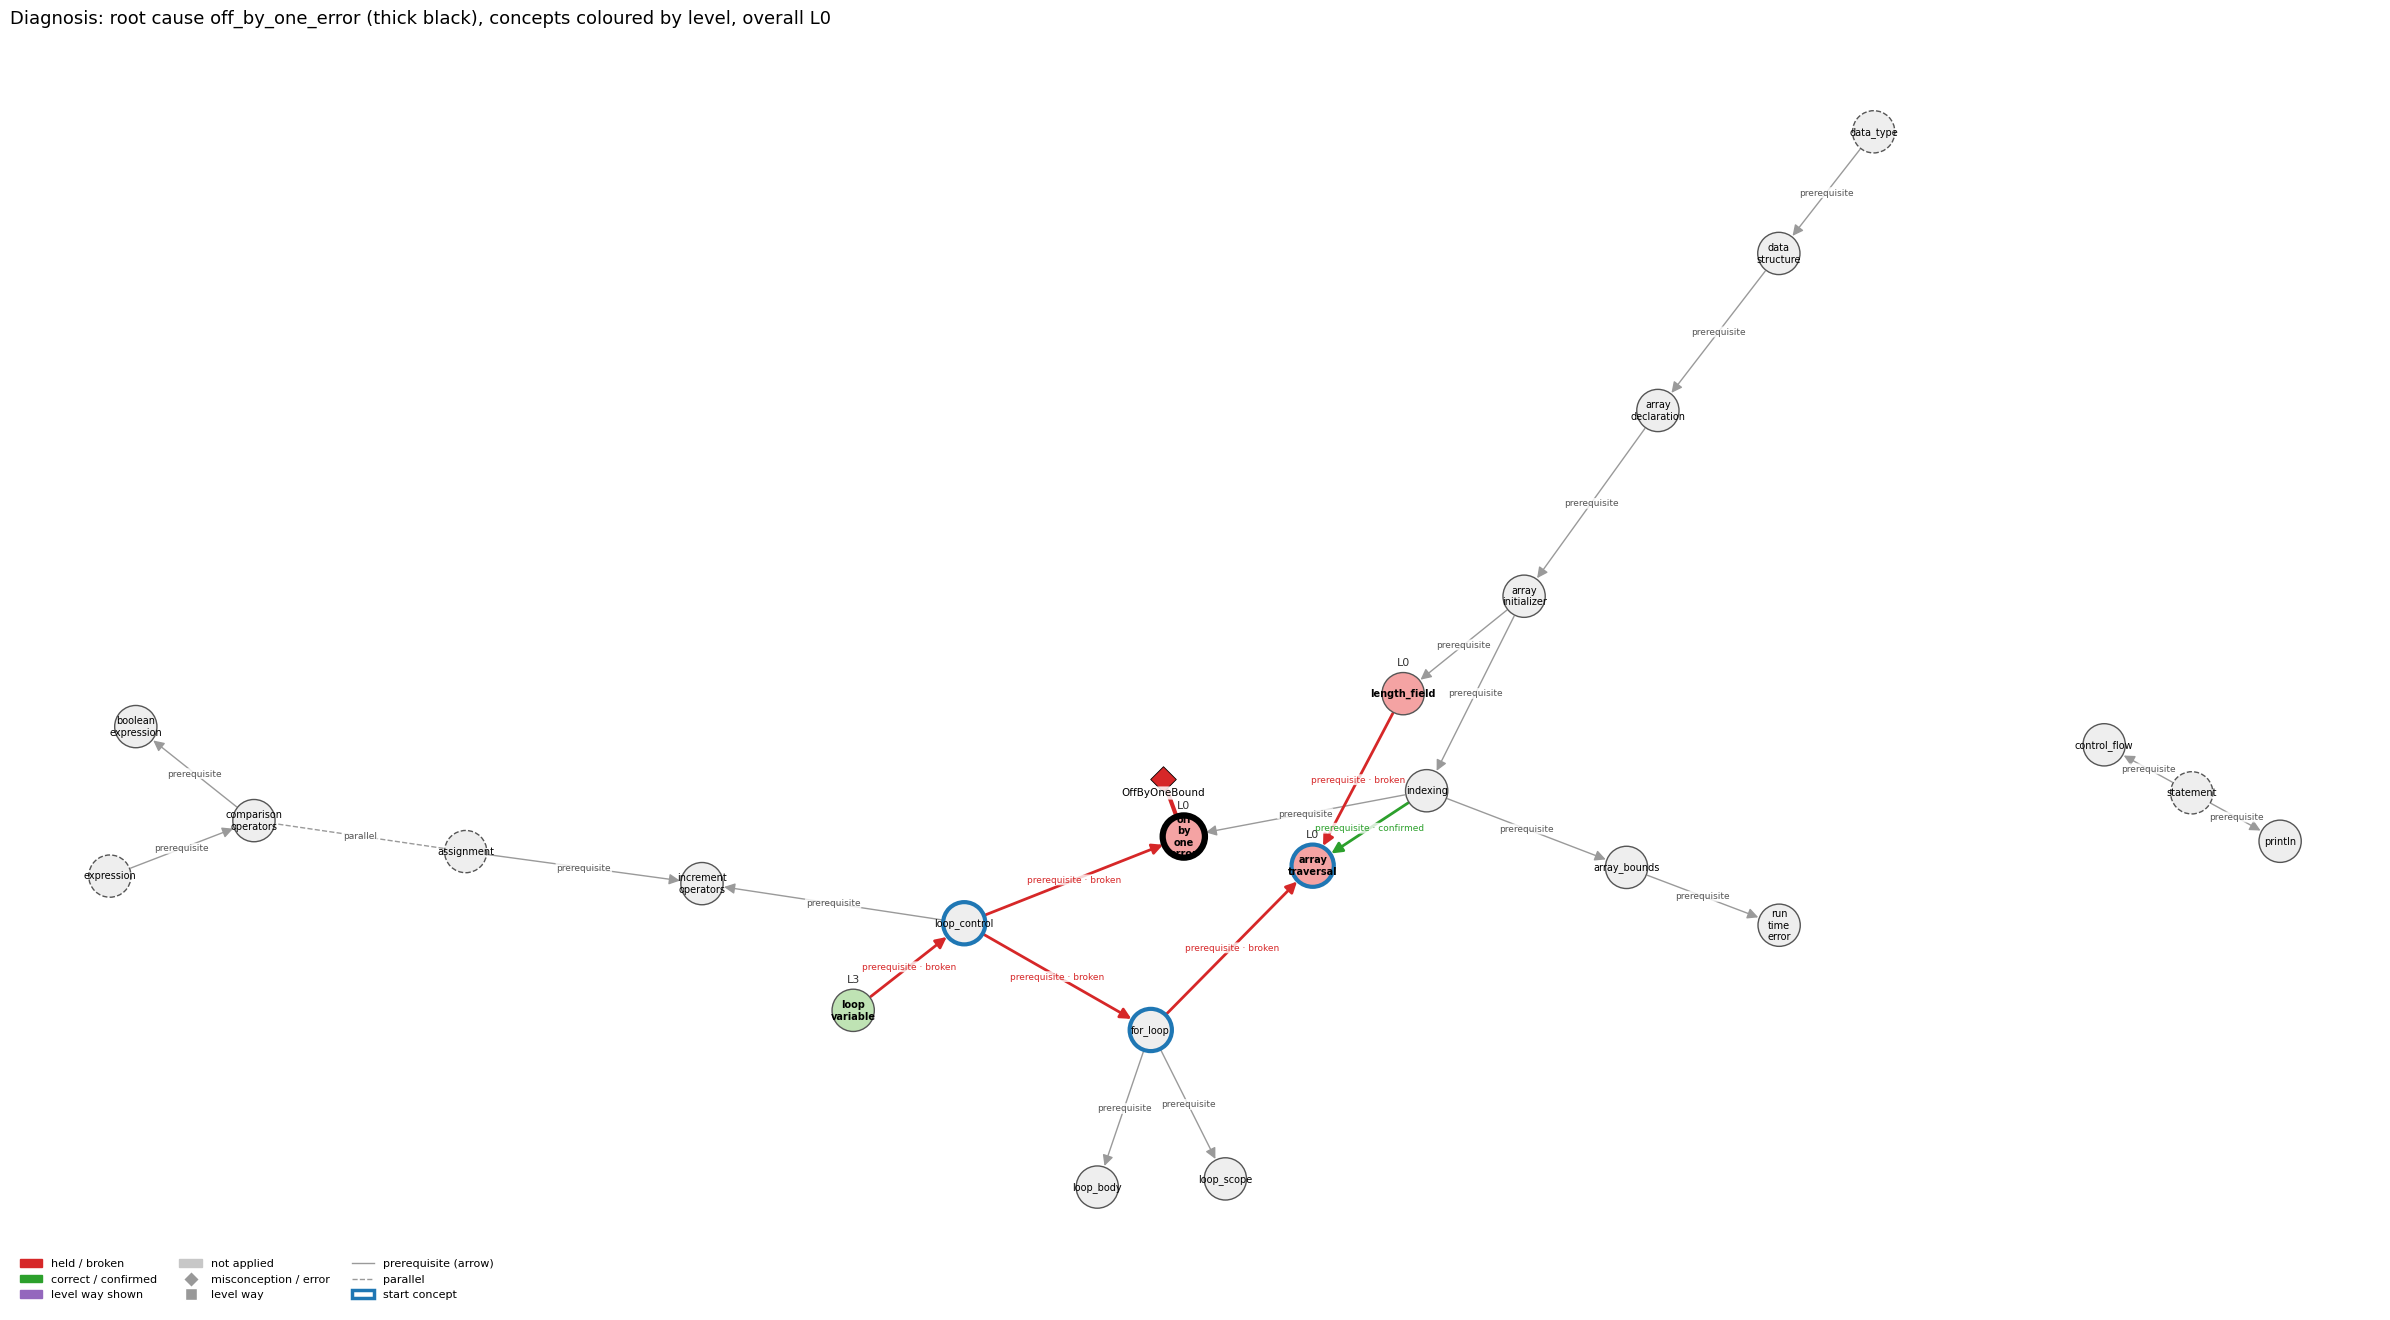


uploading MY26 to GitHub ...
Stage 1: 23 concepts, 23 concept edges, 159 misconception edges
Stage 2: backend claude-cli, model claude-opus-5-5, width 3, depth 3
MY26: held=['OffByOneBound'] root={'concept': 'off_by_one_error', 'misconception': 'OffByOneBound'} overall=L0 stop=max depth prompts={'prune': 20, 'label': 40}


page: C:\Users\magnu\OneDrive\Desktop\ES_VIterbi_Personalized_Learning\results\viewer\MY26_demo.html


To https://github.com/24prady02/Personalized_Learning_New.git
   0f7b2a4..5231015  HEAD -> Think_of_Graph
5231015 Scenario MY26: held OffByOneBound; root cause off_by_one_error; overall L0


In [6]:
# 5. Run: Stage 1 and Stage 2 on the answer in the boxes, every step shown here
# --- if cells 1 to 3 have not been run in this kernel (fresh start or restart), run them now from this notebook file
if 'diagnose' not in globals() or 'CFG_ALL' not in globals():
    import nbformat as _nbf
    from pathlib import Path as _Path
    _root = _Path.cwd().resolve()
    while not (_root / 'src' / 'traverse.py').exists() and _root.parent != _root:
        _root = _root.parent
    _nb = _nbf.read(str(_root / 'notebooks' / 'think_on_the_graph.ipynb'), as_version=4)
    for _c in _nb.cells:
        if _c.cell_type == 'code' and (_c.source.startswith('# 1. ') or _c.source.startswith('# Drawing') or _c.source.startswith('# The pipeline')):
            exec(compile(_c.source, 'setup', 'exec'), globals())
# ---

_code, _question, _answer = code_box.value.strip("\n"), question_box.value.strip(), answer_box.value.strip()
_id = id_box.value.strip() or "MY01"
if (utils.PROCESSED_DIR / f"{_id}_diagnosis.json").exists():   # that id was used by an earlier run: keep it, take the next free one
    _n = 1
    while (utils.PROCESSED_DIR / f"MY{_n:02d}_diagnosis.json").exists():
        _n += 1
    print(f"{_id} already holds an earlier run; this run is saved as MY{_n:02d}")
    _id = f"MY{_n:02d}"
if not _code.strip() or not _answer:
    print("Please fill in at least the program and the student's answer in cell 4.")
else:
    result = diagnose(_code, _question, _answer, _id, WIDTH, DEPTH, PRUNE_TOOL, BACKEND, MODEL)
    if result is not None:                        # this scenario goes to GitHub as its own commit
        import upload
        print()
        print("uploading", SCENARIO_ID, "to GitHub ...")
        print(upload.upload_run(SCENARIO_ID))

In [7]:
# 6. (Optional) Push the notebook itself, with the outputs of the last run, to GitHub. Save it first (Ctrl+S).
import upload
print(upload.upload_notebook())

On branch Think_of_Graph
Your branch is up to date with 'origin/Think_of_Graph'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	results/G.html

nothing added to commit but untracked files present (use "git add" to track)
Everything up-to-date
5231015 Scenario MY26: held OffByOneBound; root cause off_by_one_error; overall L0


In [8]:
# 7. (Optional) The raw traversal log of the last run
# Optional: change False to True (or run this block in its own cell) to use it.
if False:
    print("\n".join(LOG))